In [5]:
plt.rc('font', family='serif')
plt.rc('text', usetex=False)
plt.rc('axes', axisbelow=True)
label_size = 15
mpl.rcParams['xtick.labelsize'] = label_size 
mpl.rcParams['ytick.labelsize'] = label_size 
mpl.rcParams['axes.labelsize'] = label_size
mpl.rcParams['axes.titlesize'] = label_size
mpl.rcParams['figure.titlesize'] = label_size
mpl.rcParams['lines.markersize'] = label_size
mpl.rcParams['grid.linewidth'] = 2.5
mpl.rcParams['legend.fontsize'] = label_size


lss = ['--',  ':', '-.', '-', '--', '-.', ':', '-', '--', '-.', ':', '-']
mss = ['x', 'o', '>', 's', 'D', '>', 'D', '>', 's', 'o', 'D']

In [2]:
%cd ../src

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src


c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\IPython\core\magics\osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


In [3]:
%load_ext autoreload
%autoreload 2

In [4]:
# local modules
import dnn
import cross_validate_dnn as cv_dnn
import scaler_methods

# packages
import numpy as np
import pandas as pd
from itertools import chain
import itertools
from matplotlib.pyplot import matshow
import matplotlib.pyplot as plt
import matplotlib as mpl
import math


In [315]:
# dgp for d = 2
def gendata0(N, T, n, d, eps_N, eps_T, p, missing_pattern) : 
    """ 
    Generates Gaussian data, with latent dimension r = 2

    required : N, d are both EVEN positive integers
    """

    ## Data Matrix (N * T * n * d)
    Data = np.zeros( (N, T, n, d) )
    true_Mean = np.zeros( (N, T, d) )
    true_Cov = np.zeros( (N, T, d, d) )

    u_1 = np.random.uniform(-1, 1, N)
    u_2 = np.random.uniform(0.2, 3, N)

    v_1 = np.random.uniform(-2, 2, T)
    v_2 = np.random.uniform(0.5, 4, T)

    even_ones = np.repeat([0, 1], d/2)
    odd_ones = np.repeat([1, 0], d/2)

    for i in range(N) : 
        for t in range(T) : 
            m_it = u_1[i]*v_1[t]*(even_ones - odd_ones)
            c_it = np.diag(u_2[i]*v_2[t]*(0.5*even_ones + odd_ones))
            true_Mean[i, t, :] = m_it
            true_Cov[i, t, :, :] = c_it
            dat_mat = np.random.multivariate_normal(m_it, c_it, size = n)
            Data[i, t, :, :] = dat_mat
    
    Masking = np.zeros( (N, T) )

    ## Masking Matrix (N * T)
    zero_rows = math.floor(N**(1 - eps_N))
    zero_cols = math.floor(T**(1 - eps_T))

    # np.zeros( (zero_rows, zero_cols) )
    # np.ones( ( (N - zero_rows), zero_cols ) )
    # np.ones( ( zero_rows, (T - zero_cols) ) )
    # np.ones( ( (N - zero_rows), (T - zero_cols) ) )
    
    expit = lambda x : np.exp(x)/(1 + np.exp(x))
    beta = np.repeat((-0.1, 0.2), N/2)

    if missing_pattern == "mcar" : 
        Masking = np.reshape(np.random.binomial(1, p, (N*T)), (N, T))
    if missing_pattern == "mcar + non-positive" : 
        Masking = np.column_stack( (np.row_stack((np.zeros( (zero_rows, zero_cols) ), np.ones( ( (N - zero_rows), zero_cols ) ))), np.row_stack((np.ones( ( zero_rows, (T - zero_cols) ) ), np.ones( ( (N - zero_rows), (T - zero_cols) ) )))) )
    if missing_pattern == "mnar + non-positive" :
        Masking = np.reshape(np.random.binomial( 1, expit(sum(beta * u_1)), (N*T) ), (N, T))

    return(Data, Masking, true_Mean, true_Cov)

In [356]:
# dgp for d = 1
def gendata0_d1(N, T, n, d, eps_N, eps_T, p, missing_pattern) : 
    """ 
    Generates Gaussian data, with latent dimension r = 2

    required : N, d are both EVEN positive integers
    """

    ## Data Matrix (N * T * n * d)
    Data = np.zeros( (N, T, n, d) )
    true_Mean = np.zeros( (N, T, d) )
    true_Cov = np.zeros( (N, T, d, d) )

    u_1 = np.random.uniform(-5, 5, N)
    u_2 = np.random.uniform(0.2, 5, N)

    v_1 = np.random.uniform(-5, 5, T)
    v_2 = np.random.uniform(0.5, 6, T)

    # even_ones = np.repeat([0, 1], d/2)
    # odd_ones = np.repeat([1, 0], d/2)

    for i in range(N) : 
        for t in range(T) : 
            m_it = np.array([u_1[i]*v_1[t]])
            c_it = np.diag(np.array([(u_2[i]*v_2[t]*(0.5))]))
            true_Mean[i, t, :] = m_it
            true_Cov[i, t, :, :] = c_it
            dat_mat = np.random.multivariate_normal(m_it, c_it, size = n)
            Data[i, t, :, :] = dat_mat
    
    Masking = np.zeros( (N, T) )

    ## Masking Matrix (N * T)
    zero_rows = math.floor(N**(1 - eps_N))
    zero_cols = math.floor(T**(1 - eps_T))

    # np.zeros( (zero_rows, zero_cols) )
    # np.ones( ( (N - zero_rows), zero_cols ) )
    # np.ones( ( zero_rows, (T - zero_cols) ) )
    # np.ones( ( (N - zero_rows), (T - zero_cols) ) )
    
    expit = lambda x : np.exp(x)/(1 + np.exp(x))
    beta = np.repeat((-0.1, 0.2), N/2)

    if missing_pattern == "mcar" : 
        Masking = np.reshape(np.random.binomial(1, p, (N*T)), (N, T))
    if missing_pattern == "mcar + non-positive" : 
        Masking = np.column_stack( (np.row_stack((np.zeros( (zero_rows, zero_cols) ), np.ones( ( (N - zero_rows), zero_cols ) ))), np.row_stack((np.ones( ( zero_rows, (T - zero_cols) ) ), np.ones( ( (N - zero_rows), (T - zero_cols) ) )))) )
    if missing_pattern == "mnar + non-positive" :
        Masking = np.reshape(np.random.binomial( 1, expit(sum(beta * u_1)), (N*T) ), (N, T))

    return(Data, Masking, true_Mean, true_Cov)

In [238]:
def gendata1(N, T, n, d, eps_N, eps_T, p, missing_pattern) : 
    """ 
    Generates Gaussian mixture data, with latent dimension r = 3

    required : N, d are both even positive integers
    """

    ## Data Matrix (N * T * n * d)
    Data = np.zeros( (N, T, n, d) )

    u_1 = np.random.uniform(-1, 1, N)
    u_2 = np.random.uniform(0.2, 7, N)
    u_3 = np.random.uniform(0, 1, N)

    v_1 = np.random.uniform(-2, 2, T)
    v_2 = np.random.uniform(0.5, 8, T)
    v_3 = np.random.uniform(0, 1, T)

    # even_ones = np.repeat([0, 1], d/2)
    # odd_ones = np.repeat([1, 0], d/2)

    for i in range(N) : 
        for t in range(T) : 
            m_u = np.array([u_1[i]])
            m_v = np.array([v_1[t]])
            c_u = np.diag(np.array([u_2[i]*(0.5)]))
            c_v = np.diag(np.array([v_2[t]*(0.5)]))
            mix_weight = u_3[i]/(u_3[i] + v_3[t])
            dat_mat = np.zeros( (n, d) )
            for k in range(n) : 
                comp = np.random.binomial(1, mix_weight)
                if comp == 1 :
                    dat_mat[k, :] = np.random.multivariate_normal(m_u, c_u)
                if comp == 0 : 
                    dat_mat[k, :] = np.random.multivariate_normal(m_v, c_v)
            Data[i, t, :, :] = dat_mat
    
    Masking = np.zeros( (N, T) )

    ## Masking Matrix (N * T)
    zero_rows = math.floor(N**(1 - eps_N))
    zero_cols = math.floor(T**(1 - eps_T))

    # np.zeros( (zero_rows, zero_cols) )
    # np.ones( ( (N - zero_rows), zero_cols ) )
    # np.ones( ( zero_rows, (T - zero_cols) ) )
    # np.ones( ( (N - zero_rows), (T - zero_cols) ) )
    
    expit = lambda x : np.exp(x)/(1 + np.exp(x))
    beta = np.repeat((-0.1, 0.2), N/2)

    if missing_pattern == "mcar" : 
        Masking = np.reshape(np.random.binomial(1, p, (N*T)), (N, T))
    if missing_pattern == "mcar + non-positive" : 
        Masking = np.column_stack( (np.row_stack((np.zeros( (zero_rows, zero_cols) ), np.ones( ( (N - zero_rows), zero_cols ) ))), np.row_stack((np.ones( ( zero_rows, (T - zero_cols) ) ), np.ones( ( (N - zero_rows), (T - zero_cols) ) )))) )
    if missing_pattern == "mnar + non-positive" :
        Masking = np.reshape(np.random.binomial( 1, expit(sum(beta * u_1)), (N*T) ), (N, T))

    return(Data, Masking)

In [255]:
Z, M= gendata1(50, 200, 2, 1, eps_N = 0, eps_T = 0, p = 0.6, missing_pattern = "mcar")

In [8]:
# will make p match our setting
Z, M, true_mean, true_cov = gendata0(50, 200, 4, 2, eps_N = 0, eps_T = 0, p = 0.6, missing_pattern = "mcar")

In [357]:
Z, M, true_mean, true_cov = gendata0_d1(50, 200, 2, 1, eps_N = 0, eps_T = 0, p = 0.6, missing_pattern = "mcar")

In [358]:
np.save("sim_Z_d1_bigmeans2.npy", Z)
np.save("sim_M_d1_bigmeans2.npy", M)

In [63]:
Z.shape

(50, 200, 4, 1)

In [359]:
Z_mean = np.mean(Z, axis = -2)
Z_std = np.std(Z, axis = -2)
Z_var = np.var(Z, axis = -2)
Z_max = np.max(Z, axis = -2)
Z_median = np.median(Z, axis = -2)

# mean_Z is shape N x T x d -> 200 x 50 x 2

In [360]:
np.max(Z_var)

np.float64(83.88779844115861)

In [322]:
N, T, n, d = Z.shape

In [361]:
dists = dnn.get_col_differences(Z, M, metric = "mmd", kernel = "exponential")

In [362]:
np.max(dists[~np.isinf(dists)])

np.float64(1.5074177714292085)

In [39]:
mmd_estimates_sq_save = mmd_estimates_sq[0:37]
nn_mmd_sq_save = nn_mmd_sq[0:37]
eta_stars_save = eta_stars[0:37]
neighbors_mmd_sq_save = neighbors_mmd_sq[0:37]
all_trials_save = all_trials[0:37]

In [366]:
# for each row, search for eta, estimate the row

# this time, use even odd split instead of halves

# split_A = np.split(M, 2, axis = 1)
# split_M = np.split(Z, 2, axis = 1)

width = len(M[0])
#ws2_estimates = np.full([N, T, n], np.nan)

mmd_estimates_exp = [None] * N
#mmd_estimates_sq = [None] * N

#nn_ws2 = np.full([N, T], np.nan)
nn_mmd_exp = np.full([N, T], np.nan)
#nn_mmd_sq = np.full([N, T], np.nan)

eta_stars = np.full([N, 6], np.nan)

#neighbors_ws2 = [None] * N

neighbors_mmd_exp = [None] * N

#neighbors_mmd_sq = [None] * N

all_trials = np.full([N, 6], None, dtype = object)

for i in range(len(M)):
  print("User " + str(i))
  # sample split
  dist_A = M.copy()
  dist_A[i] = 0

  #wasserstein_diffs = dnn.get_col_differences(Z, dist_A, metric = "wasserstein2", kernel = None)
  mmd_exp_diffs = dnn.get_col_differences(Z, dist_A, metric = "mmd", kernel = "exponential")
  #mmd_sq_diffs = dnn.get_col_differences(Z, dist_A, metric = "mmd", kernel = "square")


  # s_ws2 = np.split(wasserstein_diffs, 2, axis = 0)
  # diffs_ws2_front = np.split(s_ws2[0], 2, axis = 1)[0]
  # diffs_ws2_back = np.split(s_ws2[1], 2, axis = 1)[1]

  #diffs_ws2_even = wasserstein_diffs[0::2, 0::2]
  #diffs_ws2_odd = wasserstein_diffs[1::2, 1::2]

  # s_mmd_exp = np.split(mmd_exp_diffs, 2, axis = 0)
  # diffs_mmd_exp_front = np.split(s_mmd_exp[0], 2, axis = 1)[0]
  # diffs_mmd_exp_back = np.split(s_mmd_exp[1], 2, axis = 1)[1]

  diffs_mmd_exp_even = mmd_exp_diffs[0::2, 0::2]
  diffs_mmd_exp_odd = mmd_exp_diffs[1::2, 1::2]


  # s_mmd_sq = np.split(mmd_sq_diffs, 2, axis = 0)
  # diffs_mmd_sq_front = np.split(s_mmd_sq[0], 2, axis = 1)[0]
  # diffs_mmd_sq_back = np.split(s_mmd_sq[1], 2, axis = 1)[1]

  #diffs_mmd_sq_even = mmd_sq_diffs[0::2, 0::2]
  #diffs_mmd_sq_odd = mmd_sq_diffs[1::2, 1::2]


  
  # TWO eta searches per row, one using even cols
  # the other using odd cols 

  even_M = M[:,0::2]
  odd_M = M[:,1::2]
  even_Z = Z[:, 0::2]
  odd_Z = Z[:, 1::2]
  

  # eta_star_ws2_even, tr_ws2_even = cv_dnn.search_eta(even_Z, even_M, 5, i, 
  #                                        diffs_ws2_even, dnn.estimate_row, 
  #                                        metric="wasserstein2", 
  #                                        range_min = 0, range_max = 50)
  # eta_stars[i, 0] = eta_star_ws2_even
  # all_trials[i, 0] = tr_ws2_even

  # eta_star_ws2_odd, tr_ws2_odd = cv_dnn.search_eta(odd_Z, odd_M, 5, i,
  #                                       diffs_ws2_odd, dnn.estimate_row,
  #                                       metric = "wasserstein2",
  #                                       range_min = 0, range_max = 50)
  # eta_stars[i, 1] = eta_star_ws2_odd
  # all_trials[i, 1] = tr_ws2_odd
  eta_star_mmd_exp_even, tr_mmd_exp_even = cv_dnn.search_eta(even_Z, even_M, 5, i, 
                                         diffs_mmd_exp_even, dnn.estimate_row, 
                                         metric="mmd", kernel = "exponential", 
                                         range_min = 0, range_max = 1.5)
  eta_stars[i, 2] = eta_star_mmd_exp_even
  all_trials[i, 2] = tr_mmd_exp_even
  eta_star_mmd_exp_odd, tr_mmd_exp_odd = cv_dnn.search_eta(odd_Z, odd_M, 5, i,
                                        diffs_mmd_exp_odd, dnn.estimate_row,
                                        metric = "mmd", kernel = "exponential",
                                        range_min = 0, range_max = 1.5)
  all_trials[i, 3] = tr_mmd_exp_odd
  eta_stars[i, 3] = eta_star_mmd_exp_odd
  # eta_star_mmd_sq_even, tr_mmd_sq_even = cv_dnn.search_eta(even_Z, even_M, 5, i, 
  #                                        diffs_mmd_sq_even, dnn.estimate_row, 
  #                                        metric="mmd", kernel = "square", 
  #                                        range_min = 0, range_max = 120000)
  # eta_stars[i, 4] = eta_star_mmd_sq_even
  # all_trials[i, 4] = tr_mmd_sq_even
  # eta_star_mmd_sq_odd, tr_mmd_sq_odd = cv_dnn.search_eta(odd_Z, odd_M, 5, i,
  #                                       diffs_mmd_sq_odd, dnn.estimate_row,
  #                                       metric = "mmd", kernel = "square",
  #                                       range_min = 0, range_max = 120000)
  # eta_stars[i, 5] = eta_star_mmd_sq_odd
  # all_trials[i, 5] = tr_mmd_sq_odd

  test_inds = np.nonzero(M[i] == 1)[0]
  even_test_inds = test_inds[(test_inds % 2) == 0]
  odd_test_inds = test_inds[(test_inds % 2) != 0]

  print("Estimating unit " + str(i))

  # estimate_even_ws2, nn_even_ws2, neighbors_even_ws2 = dnn.estimate_row(Z, M, i, even_test_inds, 
  #                                       wasserstein_diffs, eta_star_ws2_odd, 
  #                                       "wasserstein2", ret_nn = True)
  # estimate_even_ws2 = estimate_even_ws2[0::2]
  # nn_even_ws2 = nn_even_ws2[0::2]
  # neighbors_even_ws2 = neighbors_even_ws2[0::2]

  # estimate_odd_ws2, nn_odd_ws2, neighbors_odd_ws2 = dnn.estimate_row(Z, M, i, odd_test_inds, 
  #                                       wasserstein_diffs, eta_star_ws2_even, 
  #                                       "wasserstein2", ret_nn = True)
  # estimate_odd_ws2 = estimate_odd_ws2[1::2]
  # nn_odd_ws2 = nn_odd_ws2[1::2]
  # neighbors_odd_ws2 = neighbors_odd_ws2[1::2]

  estimate_even_mmd_exp, nn_even_mmd_exp, neighbors_even_mmd_exp = dnn.estimate_row(Z, M, i, even_test_inds,
                                            mmd_exp_diffs, eta_star_mmd_exp_odd,
                                            "mmd", ret_nn = True)
  estimate_even_mmd_exp = estimate_even_mmd_exp[0::2]
  nn_even_mmd_exp = nn_even_mmd_exp[0::2]
  neighbors_even_mmd_exp = neighbors_even_mmd_exp[0::2]

  estimate_odd_mmd_exp, nn_odd_mmd_exp, neighbors_odd_mmd_exp = dnn.estimate_row(Z, M, i, odd_test_inds,
                                            mmd_exp_diffs, eta_star_mmd_exp_even,
                                            "mmd", ret_nn = True)
  estimate_odd_mmd_exp = estimate_odd_mmd_exp[1::2]
  nn_odd_mmd_exp = nn_odd_mmd_exp[1::2]
  neighbors_odd_mmd_exp = neighbors_odd_mmd_exp[1::2]

  # estimate_even_mmd_sq, nn_even_mmd_sq, neighbors_even_mmd_sq = dnn.estimate_row(Z, M, i, even_test_inds,
  #                                           mmd_sq_diffs, eta_star_mmd_sq_odd,
  #                                           "mmd", ret_nn = True)
  # estimate_even_mmd_sq = estimate_even_mmd_sq[0::2]
  # nn_even_mmd_sq = nn_even_mmd_sq[0::2]
  # neighbors_even_mmd_sq = neighbors_even_mmd_sq[0::2]

  # estimate_odd_mmd_sq, nn_odd_mmd_sq, neighbors_odd_mmd_sq = dnn.estimate_row(Z, M, i, odd_test_inds,
  #                                           mmd_sq_diffs, eta_star_mmd_sq_even,
  #                                           "mmd", ret_nn = True)
  # estimate_odd_mmd_sq = estimate_odd_mmd_sq[1::2]
  # nn_odd_mmd_sq = nn_odd_mmd_sq[1::2]
  # neighbors_odd_mmd_sq = neighbors_odd_mmd_sq[1::2]
  
  # splice estimates together
  # est_row_ws2 = np.full([T, n], np.nan)
  # est_row_ws2[0::2] = estimate_even_ws2
  # est_row_ws2[1::2] = estimate_odd_ws2

  est_row_mmd_exp = [None] * T
  est_row_mmd_exp[0::2] = estimate_even_mmd_exp
  est_row_mmd_exp[1::2] = estimate_odd_mmd_exp

  # est_row_mmd_sq = [None] * T
  # est_row_mmd_sq[0::2] = estimate_even_mmd_sq
  # est_row_mmd_sq[1::2] = estimate_odd_mmd_sq

  # row_nn_ws2 = np.full(T, np.nan)
  # row_nn_ws2[0::2] = nn_even_ws2
  # row_nn_ws2[1::2] = nn_odd_ws2

  row_nn_mmd_exp = np.full(T, np.nan)
  row_nn_mmd_exp[0::2] = nn_even_mmd_exp
  row_nn_mmd_exp[1::2] = nn_odd_mmd_exp

  # row_nn_mmd_sq = np.full(T, np.nan)
  # row_nn_mmd_sq[0::2] = nn_even_mmd_sq
  # row_nn_mmd_sq[1::2] = nn_odd_mmd_sq

  # row_neighbors_ws2 = [None] * T
  # row_neighbors_ws2[0::2] = neighbors_even_ws2
  # row_neighbors_ws2[1::2] = neighbors_odd_ws2

  row_neighbors_mmd_exp = [None] * T
  row_neighbors_mmd_exp[0::2] = neighbors_even_mmd_exp
  row_neighbors_mmd_exp[1::2] = neighbors_odd_mmd_exp

  # row_neighbors_mmd_sq = [None] * T
  # row_neighbors_mmd_sq[0::2] = neighbors_even_mmd_sq
  # row_neighbors_mmd_sq[1::2] = neighbors_odd_mmd_sq

  # est_row_ws2 = np.concatenate((estimate_front_ws2, estimate_back_ws2), axis = 0)
  #est_row_mmd_exp = estimate_front_mmd_exp + estimate_back_mmd_exp
  # est_row_mmd_sq = estimate_front_mmd_sq + estimate_back_mmd_sq

  # row_nn_ws2 = np.concatenate((nn_front_ws2, nn_back_ws2), axis = 0)
  #row_nn_mmd_exp = np.concatenate((nn_front_mmd_exp, nn_back_mmd_exp), axis = 0)
  # row_nn_mmd_sq = np.concatenate((nn_front_mmd_sq, nn_back_mmd_sq), axis = 0)

  # row_neighbors_ws2 = neighbors_front_ws2 + neighbors_back_ws2
  #row_neighbors_mmd_exp = neighbors_front_mmd_exp + neighbors_back_mmd_exp
  # row_neighbors_mmd_sq = neighbors_front_mmd_sq + neighbors_back_mmd_sq

  # neighbors_ws2[i] = row_neighbors_ws2
  neighbors_mmd_exp[i] = row_neighbors_mmd_exp
  #neighbors_mmd_sq[i] = row_neighbors_mmd_sq

  # ws2_estimates[i] = est_row_ws2
  mmd_estimates_exp[i] = est_row_mmd_exp
  #mmd_estimates_sq[i] = est_row_mmd_sq

  # nn_ws2[i] = row_nn_ws2
  nn_mmd_exp[i] = row_nn_mmd_exp
  #nn_mmd_sq[i] = row_nn_mmd_sq

User 0
100%|██████████| 200/200 [00:04<00:00, 47.64trial/s, best loss: 0.1879959634293308]
Estimating unit 0
User 1
100%|██████████| 200/200 [00:05<00:00, 39.52trial/s, best loss: 0.1405635617122696]
Estimating unit 1
User 2
100%|██████████| 200/200 [00:05<00:00, 38.00trial/s, best loss: 0.19585942364375414]
Estimating unit 2
User 3
100%|██████████| 200/200 [00:05<00:00, 36.39trial/s, best loss: 0.21220763554666924]
Estimating unit 3
User 4
100%|██████████| 200/200 [00:06<00:00, 28.95trial/s, best loss: 0.12824237696899482]
Estimating unit 4
User 5
100%|██████████| 200/200 [00:05<00:00, 38.97trial/s, best loss: 0.14362694157383013]
Estimating unit 5
User 6
100%|██████████| 200/200 [00:05<00:00, 39.52trial/s, best loss: 0.09045732454046788]
Estimating unit 6
User 7
100%|██████████| 200/200 [00:05<00:00, 39.96trial/s, best loss: 0.12779567209751216]
Estimating unit 7
User 8
100%|██████████| 200/200 [00:04<00:00, 40.51trial/s, best loss: 0.060542567322619]
Estimating unit 8
User 9
100%|██

In [375]:
dists = scaler_methods.all_dissims(Z_max, M, ax = 1)

In [377]:
np.max(dists[~np.isinf(dists)])

# mean 0 to 99
# std 0 to 0.8
# var 0 to 54
# median 0 to 00
# max 0 to 101


np.float64(101.54380900509342)

In [41]:
mmd_estimates_sq[0:37] = mmd_estimates_sq_save

In [378]:
# snn estimates
# for each row, search for eta, estimate the row
# this time, split by users rather than time
split_A = np.split(M, 2, axis = 1)

split_M_mean = np.split(Z_mean, 2, axis = 1)
split_M_std = np.split(Z_std, 2, axis = 1)
split_M_var = np.split(Z_var, 2, axis = 1)
split_M_max = np.split(Z_max, 2, axis = 1)
split_M_median = np.split(Z_median, 2, axis = 1)

width = len(M[0])

snn_mean_estimates = np.full([N, T, d], np.nan)
snn_std_estimates = np.full([N, T, d], np.nan)
snn_var_estimates = np.full([N, T, d], np.nan)
snn_max_estimates = np.full([N, T, d], np.nan)
snn_median_estimates = np.full([N, T, d], np.nan)

#ws2_estimates = np.full([N, T, n], np.nan)

#mmd_estimates_exp = [None] * N
#mmd_estimates_sq = [None] * N

#nn_ws2 = np.full([N, T], np.nan)
#nn_mmd_exp = np.full([N, T], np.nan)
#nn_mmd_sq = np.full([N, T], np.nan)

#eta_stars = np.full([37, 6], np.nan)

#neighbors_ws2 = [None] * N

#neighbors_mmd_exp = [None] * N

#neighbors_mmd_sq = [None] * N

for i in range(len(M)):
  print("User " + str(i))
  # sample split
  dist_A = M.copy()
  dist_A[i] = 0

  # wasserstein_diffs = dnn.get_col_differences(Z, dist_A, metric = "wasserstein2", kernel = None)
  # mmd_exp_diffs = dnn.get_col_differences(Z, dist_A, metric = "mmd", kernel = "exponential")
  # mmd_sq_diffs = dnn.get_col_differences(Z, dist_A, metric = "mmd", kernel = "square")

  snn_mean_dissims = scaler_methods.all_dissims(Z_mean, dist_A, ax = 1)
  snn_std_dissims = scaler_methods.all_dissims(Z_std, dist_A, ax = 1)
  snn_var_dissims = scaler_methods.all_dissims(Z_var, dist_A, ax = 1)
  snn_max_dissims = scaler_methods.all_dissims(Z_max, dist_A, ax = 1)
  snn_median_dissims = scaler_methods.all_dissims(Z_median, dist_A, ax = 1)

  diffs_snn_even_mean = snn_mean_dissims[0::2, 0::2]
  diffs_snn_even_std = snn_std_dissims[0::2, 0::2]
  diffs_snn_even_var = snn_var_dissims[0::2, 0::2]
  diffs_snn_even_median = snn_median_dissims[0::2, 0::2]
  diffs_snn_even_max = snn_max_dissims[0::2, 0::2]

  diffs_snn_odd_mean = snn_mean_dissims[1::2, 1::2]
  diffs_snn_odd_std = snn_std_dissims[1::2, 1::2]
  diffs_snn_odd_var = snn_var_dissims[1::2, 1::2]
  diffs_snn_odd_median = snn_median_dissims[1::2, 1::2]
  diffs_snn_odd_max = snn_max_dissims[1::2, 1::2]
  
  # s_snn_mean = np.split(snn_mean_dissims, 2, axis = 0)
  # s_snn_std = np.split(snn_std_dissims, 2, axis = 0)
  # s_snn_var = np.split(snn_var_dissims, 2, axis = 0)
  # s_snn_max = np.split(snn_max_dissims, 2, axis = 0)
  # s_snn_median = np.split(snn_median_dissims, 2, axis = 0)
  
  # diffs_snn_front_mean = np.split(s_snn_mean[0], 2, axis = 1)[0]
  # diffs_snn_back_mean = np.split(s_snn_mean[1], 2, axis = 1)[1]
  
  # diffs_snn_front_std = np.split(s_snn_std[0], 2, axis = 1)[0]
  # diffs_snn_back_std = np.split(s_snn_std[1], 2, axis = 1)[1]

  # diffs_snn_front_var = np.split(s_snn_var[0], 2, axis = 1)[0]
  # diffs_snn_back_var = np.split(s_snn_var[1], 2, axis = 1)[1]

  # diffs_snn_front_max = np.split(s_snn_max[0], 2, axis = 1)[0]
  # diffs_snn_back_max = np.split(s_snn_max[1], 2, axis = 1)[1]

  # diffs_snn_front_median = np.split(s_snn_median[0], 2, axis = 1)[0]
  # diffs_snn_back_median = np.split(s_snn_median[1], 2, axis = 1)[1]


  # s_mmd_exp = np.split(mmd_exp_diffs, 2, axis = 0)
  # diffs_mmd_exp_front = np.split(s_mmd_exp[0], 2, axis = 1)[0]
  # diffs_mmd_exp_back = np.split(s_mmd_exp[1], 2, axis = 1)[1]

  # s_mmd_sq = np.split(mmd_sq_diffs, 2, axis = 0)
  # diffs_mmd_sq_front = np.split(s_mmd_sq[0], 2, axis = 1)[0]
  # diffs_mmd_sq_back = np.split(s_mmd_sq[1], 2, axis = 1)[1]

  
  # TWO eta searches per row, one using the front half
  # the other using the back half 

  # front_M = split_A[0]
  # back_M = split_A[1]

  # front_Z_mean = split_M_mean[0]
  # back_Z_mean = split_M_mean[1]
  # front_Z_std = split_M_std[0]
  # back_Z_std = split_M_std[1]
  # front_Z_var = split_M_var[0]
  # back_Z_var = split_M_var[1]
  # front_Z_max = split_M_max[0]
  # back_Z_max = split_M_max[1]
  # front_Z_median = split_M_median[0]
  # back_Z_median = split_M_median[1]

  even_Z_mean = Z_mean[:, 0::2]
  odd_Z_mean = Z_mean[:, 1::2]
  even_Z_std = Z_std[:, 0::2]
  odd_Z_std = Z_std[:, 1::2]
  even_Z_var = Z_var[:, 0::2]
  odd_Z_var = Z_var[:, 1::2]
  even_Z_median = Z_median[:, 0::2]
  odd_Z_median = Z_median[:, 1::2]
  even_Z_max = Z_max[:, 0::2]
  odd_Z_max = Z_max[:, 1::2]

  even_M = M[:, 0::2]
  odd_M = M[:, 1::2]

  print(diffs_snn_even_mean.shape)
  # mean 0-150000
# std 0-51000
# var 0-2000000000
# max 0-450000
# median 0-170000
  
# mean 0 to 1.5
# std 0 to 1
# var 0 to 15
# median 0 to 1.5
# max 0 to 3

# mean 0 to 1
# std 0 to 0.3
# var 0 to 3
# median 0 to 1
# max 0 to 1

# mean 0 to 2
# std 0 to 1
# var 0 to 55
# median 0 to 2
# max 0 to 3.5

# mean 0 to 80
# std 0 to 0.6
# var 0 to 26
# median 0 to 80
# max 0 to 80

# mean 0 to 99
# std 0 to 0.8
# var 0 to 54
# median 0 to 00
# max 0 to 101

  eta_star_snn_even_mean, _ = scaler_methods.search_eta(even_Z_mean, even_M, 5, i, 
                                         diffs_snn_even_mean, range_min = 0, range_max = 99)

  eta_star_snn_odd_mean, _ = scaler_methods.search_eta(odd_Z_mean, odd_M, 5, i,
                                        diffs_snn_odd_mean, range_min = 0, range_max = 99)
  
  eta_star_snn_even_std, _ = scaler_methods.search_eta(even_Z_std, even_M, 5, i, 
                                         diffs_snn_even_std, range_min = 0, range_max = 0.8)

  eta_star_snn_odd_std, _ = scaler_methods.search_eta(odd_Z_std, odd_M, 5, i,
                                        diffs_snn_odd_std, range_min = 0, range_max = 0.8)
  
  eta_star_snn_even_var, _ = scaler_methods.search_eta(even_Z_var, even_M, 5, i, 
                                         diffs_snn_even_var, range_min = 0, range_max = 54)

  eta_star_snn_odd_var, _ = scaler_methods.search_eta(odd_Z_var, odd_M, 5, i,
                                        diffs_snn_odd_var, range_min = 0, range_max = 54)
  
  eta_star_snn_even_median, _ = scaler_methods.search_eta(even_Z_median, even_M, 5, i, 
                                         diffs_snn_even_median, range_min = 0, range_max = 99)

  eta_star_snn_odd_median, _ = scaler_methods.search_eta(odd_Z_median, odd_M, 5, i,
                                        diffs_snn_odd_median, range_min = 0, range_max = 99)
  
  eta_star_snn_even_max, _ = scaler_methods.search_eta(even_Z_max, even_M, 5, i, 
                                         diffs_snn_even_max, range_min = 0, range_max = 101)

  eta_star_snn_odd_max, _ = scaler_methods.search_eta(odd_Z_max, odd_M, 5, i,
                                        diffs_snn_odd_max, range_min = 0, range_max = 101)

  # eta_star_snn_front_std, _ = scaler_methods.search_eta(front_Z_std, front_M, 5, i, 
  #                                        diffs_snn_front_std, range_min = 0, range_max = 51000)

  # eta_star_snn_back_std, _ = scaler_methods.search_eta(back_Z_std, back_M, 5, i,
  #                                       diffs_snn_back_std, range_min = 0, range_max = 51000)

  # eta_star_snn_front_var, _ = scaler_methods.search_eta(front_Z_var, front_M, 5, i, 
  #                                        diffs_snn_front_var, range_min = 0, range_max = 2000000000)

  # eta_star_snn_back_var, _ = scaler_methods.search_eta(back_Z_var, back_M, 5, i,
  #                                       diffs_snn_back_var, range_min = 0, range_max = 2000000000)

  # eta_star_snn_front_max, _ = scaler_methods.search_eta(front_Z_max, front_M, 5, i,
  #                                       diffs_snn_front_max, range_min = 0, range_max = 450000)

  # eta_star_snn_back_max, _ = scaler_methods.search_eta(back_Z_max, back_M, 5, i,
  #                                       diffs_snn_back_max, range_min = 0, range_max = 450000)
  
  # eta_star_snn_front_median, _ = scaler_methods.search_eta(front_Z_median, front_M, 5, i,
  #                                       diffs_snn_front_median, range_min = 0, range_max = 170000)

  # eta_star_snn_back_median, _ = scaler_methods.search_eta(back_Z_median, back_M, 5, i,
  #                                       diffs_snn_back_median, range_min = 0, range_max = 170000)


  # estimate first half using eta from second
  test_inds = np.nonzero(M[i] == 1)[0]
  # front_test_inds = test_inds[test_inds < (width / 2)]
  # back_test_inds = test_inds[test_inds >= (width / 2)]
  even_test_inds = test_inds[(test_inds % 2) == 0]
  odd_test_inds = test_inds[(test_inds % 2) != 0]


  print("Estimating unit " + str(i))

  estimate_even_snn_mean = scaler_methods.estimate_row(Z_mean, M, i, even_test_inds, 
                                        snn_mean_dissims, eta_star_snn_odd_mean, ax = 1)

  estimate_even_snn_mean = estimate_even_snn_mean[0::2]

  estimate_odd_snn_mean = scaler_methods.estimate_row(Z_mean, M, i, odd_test_inds, 
                                          snn_mean_dissims, eta_star_snn_even_mean, ax = 1)
  estimate_odd_snn_mean = estimate_odd_snn_mean[1::2]

  # std
  estimate_even_snn_std = scaler_methods.estimate_row(Z_std, M, i, even_test_inds, 
                                        snn_std_dissims, eta_star_snn_odd_std, ax = 1)

  estimate_even_snn_std = estimate_even_snn_std[0::2]

  estimate_odd_snn_std = scaler_methods.estimate_row(Z_std, M, i, odd_test_inds, 
                                          snn_std_dissims, eta_star_snn_even_std, ax = 1)
  estimate_odd_snn_std = estimate_odd_snn_std[1::2]
  # var
  estimate_even_snn_var = scaler_methods.estimate_row(Z_var, M, i, even_test_inds, 
                                        snn_var_dissims, eta_star_snn_odd_var, ax = 1)

  estimate_even_snn_var = estimate_even_snn_var[0::2]

  estimate_odd_snn_var = scaler_methods.estimate_row(Z_var, M, i, odd_test_inds, 
                                          snn_var_dissims, eta_star_snn_even_var, ax = 1)
  estimate_odd_snn_var = estimate_odd_snn_var[1::2]

  # median
  estimate_even_snn_median = scaler_methods.estimate_row(Z_median, M, i, even_test_inds, 
                                        snn_median_dissims, eta_star_snn_odd_median, ax = 1)

  estimate_even_snn_median = estimate_even_snn_median[0::2]

  estimate_odd_snn_median = scaler_methods.estimate_row(Z_median, M, i, odd_test_inds, 
                                          snn_median_dissims, eta_star_snn_even_median, ax = 1)
  estimate_odd_snn_median = estimate_odd_snn_median[1::2]

  # max
  estimate_even_snn_max = scaler_methods.estimate_row(Z_max, M, i, even_test_inds, 
                                        snn_max_dissims, eta_star_snn_odd_max, ax = 1)

  estimate_even_snn_max = estimate_even_snn_max[0::2]

  estimate_odd_snn_max = scaler_methods.estimate_row(Z_max, M, i, odd_test_inds, 
                                          snn_max_dissims, eta_star_snn_even_max, ax = 1)
  estimate_odd_snn_max = estimate_odd_snn_max[1::2]



  
  # concat estimates together
  est_row_snn_mean = np.full([T, d], np.nan)
  est_row_snn_mean[0::2] = estimate_even_snn_mean
  est_row_snn_mean[1::2] = estimate_odd_snn_mean

  est_row_snn_std = np.full([T, d], np.nan)
  est_row_snn_std[0::2] = estimate_even_snn_std
  est_row_snn_std[1::2] = estimate_odd_snn_std

  est_row_snn_var = np.full([T, d], np.nan)
  est_row_snn_var[0::2] = estimate_even_snn_var
  est_row_snn_var[1::2] = estimate_odd_snn_var

  est_row_snn_median = np.full([T, d], np.nan)
  est_row_snn_median[0::2] = estimate_even_snn_median
  est_row_snn_median[1::2] = estimate_odd_snn_median

  est_row_snn_max = np.full([T, d], np.nan)
  est_row_snn_max[0::2] = estimate_even_snn_max
  est_row_snn_max[1::2] = estimate_odd_snn_max
  # est_row_snn_mean = np.concatenate((estimate_even_snn_mean, estimate_odd_snn_mean), axis = 0)
  # est_row_snn_std = np.concatenate((estimate_even_snn_std, estimate_odd_snn_std), axis = 0)
  # est_row_snn_var = np.concatenate((estimate_even_snn_var, estimate_odd_snn_var), axis = 0)
  # est_row_snn_max = np.concatenate((estimate_even_snn_max, estimate_odd_snn_max), axis = 0)
  # est_row_snn_median = np.concatenate((estimate_even_snn_median, estimate_odd_snn_median), axis = 0)


  snn_mean_estimates[i] = est_row_snn_mean
  snn_std_estimates[i] = est_row_snn_std
  snn_var_estimates[i] = est_row_snn_var
  snn_max_estimates[i] = est_row_snn_max
  snn_median_estimates[i] = est_row_snn_median


User 0
(100, 100)
100%|██████████| 200/200 [00:01<00:00, 113.81trial/s, best loss: 2.373972811526624]
Estimating unit 0
User 1
(100, 100)
100%|██████████| 200/200 [00:01<00:00, 122.04trial/s, best loss: 3.938461100560646]
Estimating unit 1
User 2
(100, 100)
100%|██████████| 200/200 [00:01<00:00, 131.30trial/s, best loss: 7.349084287452271]
Estimating unit 2
User 3
(100, 100)
100%|██████████| 200/200 [00:01<00:00, 125.27trial/s, best loss: 4.616794607237027]
Estimating unit 3
User 4
(100, 100)
100%|██████████| 200/200 [00:01<00:00, 128.27trial/s, best loss: 6.648953116266301]
Estimating unit 4
User 5
(100, 100)
100%|██████████| 200/200 [00:01<00:00, 130.67trial/s, best loss: 3.3525039392062412]
Estimating unit 5
User 6
(100, 100)
100%|██████████| 200/200 [00:01<00:00, 126.58trial/s, best loss: 5.660315142317913]
Estimating unit 6
User 7
(100, 100)
100%|██████████| 200/200 [00:01<00:00, 131.62trial/s, best loss: 3.011743767443993]
Estimating unit 7
User 8
(100, 100)
100%|██████████| 200/

In [379]:
np.save('snn_mean_estimates_v9_bigmean2.npy', snn_mean_estimates) 
np.save('snn_std_estimates_v9_bigmean2.npy', snn_std_estimates) 
np.save('snn_var_estimates_v9_bigmean2.npy', snn_var_estimates) 
np.save('snn_max_estimates_v9_bigmean2.npy', snn_max_estimates) 
np.save('snn_median_estimates_v9_bigmean2.npy', snn_median_estimates) 

In [71]:
mmd_estimates_sq[40:45]

[[array([[-1.39419724e+00,  2.17131690e-01],
         [ 8.39053039e-02, -3.12776167e-01],
         [-5.73527300e-01,  8.64171942e-01],
         [ 8.52369765e-01,  2.76486759e-01],
         [ 3.25275280e-01, -1.34888929e+00],
         [-2.16932178e+00, -8.00719445e-01],
         [-7.14612825e-01,  1.44681155e+00],
         [-8.63675061e-01, -7.33033653e-01],
         [ 1.35161096e+00,  1.73313042e+00],
         [ 2.23890596e+00, -3.30887749e-01],
         [ 5.17303127e-01, -9.02174809e-01],
         [-1.20406997e+00,  1.28297444e+00],
         [ 2.01038965e+00,  1.93186828e-01],
         [ 6.15964653e-01,  9.12690281e-01],
         [ 8.62324025e-01, -2.20090798e+00],
         [-9.58949664e-01, -9.52265590e-02],
         [-1.10533631e+00, -1.50357754e+00],
         [-1.18500890e+00, -5.72068790e-01],
         [ 1.93519342e+00,  7.67858796e-01],
         [-1.24552698e+00, -5.87469503e-01],
         [-1.00346956e+00,  1.62660560e+00],
         [ 8.17657031e-02, -1.57659341e-01],
         [

In [385]:
np.save('mmd_estimates_exp_simulated_v7_bigmean2.npy', np.array(mmd_estimates_exp, dtype=object), allow_pickle=True)

In [305]:
snn_mean_estimates = np.load('snn_mean_estimates_v4.npy', allow_pickle = True)
snn_std_estimates = np.load('snn_std_estimates_v4.npy', allow_pickle = True)
snn_var_estimates = np.load('snn_var_estimates_v4.npy', allow_pickle = True)
snn_median_estimates = np.load('snn_median_estimates_v4.npy', allow_pickle = True)

In [306]:
mmd_estimates_sq = np.load('mmd_estimates_sq_simulated_v2.npy', allow_pickle = True)

In [22]:
np.sum(np.any(~np.isnan(snn_mean_estimates) & ~np.isinf(snn_mean_estimates), axis = -1))

np.int64(5941)

In [81]:
np.sum(M == 1)

np.int64(5984)

In [381]:
meanfilter = np.all(~np.isnan(snn_mean_estimates) & ~np.isinf(snn_mean_estimates), axis = -1)
stdfilter = np.all(~np.isnan(snn_std_estimates) & ~np.isinf(snn_std_estimates), axis = -1)
varfilter = np.all(~np.isnan(snn_var_estimates) & ~np.isinf(snn_var_estimates), axis = -1)
maxfilter = np.all(~np.isnan(snn_max_estimates) & ~np.isinf(snn_max_estimates), axis = -1)
medianfilter = np.all(~np.isnan(snn_median_estimates) & ~np.isinf(snn_median_estimates), axis = -1)

In [382]:
l2_error_snn_mean = np.full((N, T), np.nan)
l2_error_snn_std = np.full((N, T), np.nan)
l2_error_snn_var = np.full((N, T), np.nan)
l2_error_snn_max = np.full((N, T), np.nan)
l2_error_snn_median = np.full((N, T), np.nan)

l2_error_snn_mean[meanfilter] = np.linalg.norm((Z_mean[meanfilter] - snn_mean_estimates[meanfilter])**2, axis = -1)
l2_error_snn_std[stdfilter] = np.linalg.norm((Z_std[stdfilter] - snn_std_estimates[stdfilter])**2, axis = -1)
l2_error_snn_var[varfilter] = np.linalg.norm((Z_var[varfilter] - snn_var_estimates[varfilter])**2, axis = -1)
l2_error_snn_max[maxfilter] = np.linalg.norm((Z_max[maxfilter] - snn_max_estimates[maxfilter])**2, axis = -1)
l2_error_snn_median[medianfilter] = np.linalg.norm((Z_median[medianfilter] - snn_median_estimates[medianfilter])**2, axis = -1)

In [383]:
l2_error_snn_mean = l2_error_snn_mean.flatten()
l2_error_snn_std = l2_error_snn_std.flatten()
l2_error_snn_var = l2_error_snn_var.flatten()

l2_error_snn_median = l2_error_snn_median.flatten()


l2_error_snn_max= l2_error_snn_max.flatten()


In [27]:
mmd_estimates_sq[0][1].shape

(164, 2)

In [ ]:
nans = 0
mmd_sq_mean = np.full([N, T, d], np.nan)
mmd_sq_std = np.full([N, T, d], np.nan)
mmd_sq_var = np.full([N, T, d], np.nan)
mmd_sq_max = np.full([N, T, d], np.nan)
mmd_sq_median = np.full([N, T, d], np.nan)
for i in range(N):
  for j in range(T):
    if mmd_estimates_sq[i][j] is None:
      continue
    mmd_sq_mean[i, j] = np.nanmean(mmd_estimates_sq[i][j], axis = 0)
    mmd_sq_std[i, j] = np.nanstd(mmd_estimates_sq[i][j], axis = 0)
    mmd_sq_var[i, j] = np.nanvar(mmd_estimates_sq[i][j], axis = 0)
    mmd_sq_max[i, j] = np.nanmax(mmd_estimates_sq[i][j], axis = 0)
    mmd_sq_median[i, j] = np.nanmedian(mmd_estimates_sq[i][j], axis = 0)

In [386]:
nans = 0
mmd_exp_mean = np.full([N, T, d], np.nan)
mmd_exp_std = np.full([N, T, d], np.nan)
mmd_exp_var = np.full([N, T, d], np.nan)
mmd_exp_max = np.full([N, T, d], np.nan)
mmd_exp_median = np.full([N, T, d], np.nan)
for i in range(N):
  for j in range(T):
    if mmd_estimates_exp[i][j] is None:
      continue
    mmd_exp_mean[i, j] = np.nanmean(mmd_estimates_exp[i][j], axis = 0)
    mmd_exp_std[i, j] = np.nanstd(mmd_estimates_exp[i][j], axis = 0)
    mmd_exp_var[i, j] = np.nanvar(mmd_estimates_exp[i][j], axis = 0)
    mmd_exp_max[i, j] = np.nanmax(mmd_estimates_exp[i][j], axis = 0)
    mmd_exp_median[i, j] = np.nanmedian(mmd_estimates_exp[i][j], axis = 0)

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1882: RuntimeWarning: invalid value encountered in subtract
  np.subtract(arr, avg, out=arr, casting='unsafe', where=where)


In [ ]:
mmd_sq_mean

In [347]:
l2_error_mmdsq_mean = np.linalg.norm((Z_mean - mmd_sq_mean)**2, axis = -1).flatten()
l2_error_mmdsq_std = np.linalg.norm((Z_std - mmd_sq_std)**2, axis = -1).flatten()
l2_error_mmdsq_var = np.linalg.norm((Z_var - mmd_sq_var)**2, axis = -1).flatten()
l2_error_mmdsq_max = np.linalg.norm((Z_max - mmd_sq_max)**2, axis = -1).flatten()
l2_error_mmdsq_median = np.linalg.norm((Z_median - mmd_sq_median)**2, axis = -1).flatten()

In [387]:
l2_error_mmdexp_mean = np.linalg.norm((Z_mean - mmd_exp_mean)**2, axis = -1).flatten()
l2_error_mmdexp_std = np.linalg.norm((Z_std - mmd_exp_std)**2, axis = -1).flatten()
l2_error_mmdexp_var = np.linalg.norm((Z_var - mmd_exp_var)**2, axis = -1).flatten()
l2_error_mmdexp_max = np.linalg.norm((Z_max - mmd_exp_max)**2, axis = -1).flatten()
l2_error_mmdexp_median = np.linalg.norm((Z_median - mmd_exp_median)**2, axis = -1).flatten()

In [42]:
l2_error_mmdsq_mean.shape

(10000,)

In [388]:
# all neighbors
mean_plots = np.array([l2_error_mmdexp_mean, l2_error_snn_mean])
std_plots = np.array([l2_error_mmdexp_std, l2_error_snn_std])
var_plots = np.array([l2_error_mmdexp_var, l2_error_snn_var])
median_plots = np.array([l2_error_mmdexp_median, l2_error_snn_median])
max_plots = np.array([l2_error_mmdexp_max, l2_error_snn_max])


In [38]:
import seaborn as sns

[[       nan        nan]
 [0.0116616  0.10666126]
 [0.05311934 0.3607118 ]
 ...
 [       nan        nan]
 [8.31848854 6.87483158]
 [3.78506583 2.03628934]]


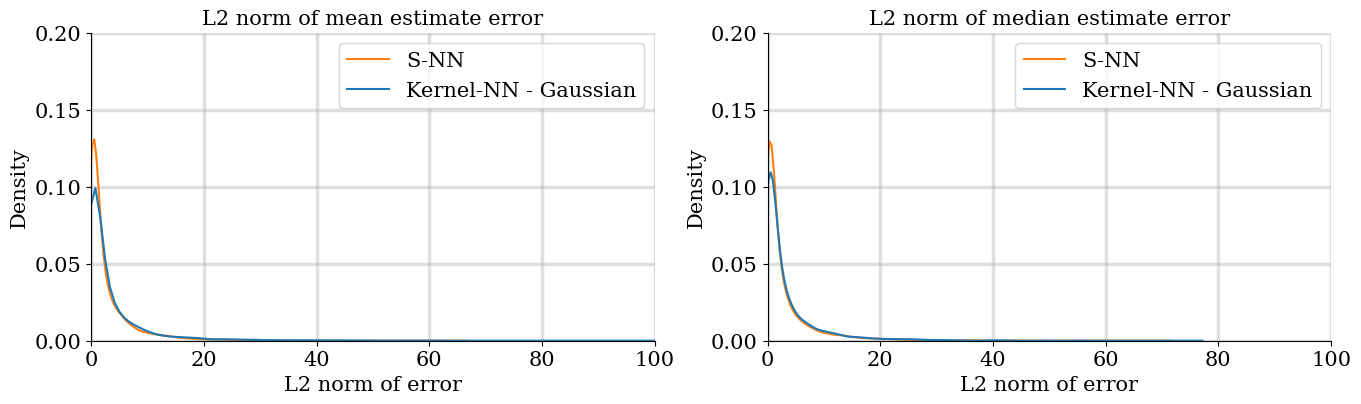

In [390]:
#ax = plt.gca()

fig, (ax1, ax2) = plt.subplots(figsize = (16, 4), ncols = 2)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)

ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.4)


labels = ["S-NN", "Kernel-NN - Gaussian"]
print(mean_plots.T)
sns.kdeplot(mean_plots.T, ax = ax1)
sns.kdeplot(median_plots.T, ax = ax2)
ax1.set_ylim([0, 0.2])
ax2.set_ylim([0, 0.2])
ax1.set_xlim([0, 100])
ax2.set_xlim([0, 100])
ax1.legend(labels = labels)
ax2.legend(labels = labels)

ax2.set_xlabel("L2 norm of error")
ax1.set_xlabel("L2 norm of error")
#ax1.set_xticklabels(labels, rotation = 45, ha = 'right')
#ax2.set_xticklabels(labels, rotation = 45, ha = 'right')

# ax1.annotate('Outliers above', xy=(-0.3, 20), xytext=(-0.3, 15),
#              arrowprops=dict(facecolor='black', shrink=0.05),
#              )
# ax2.annotate('Outliers above', xy=(-0.3, 20), xytext=(-0.3, 15),
#   arrowprops=dict(facecolor='black', shrink=0.05),
#   )
ax1.set_title("L2 norm of mean estimate error")
ax2.set_title("L2 norm of median estimate error")

#ax1.set_ylabel("L2 error")

plt.savefig("d1_gauss_bigmean_median_kde_expkern.pdf", bbox_inches = "tight")

[[       nan        nan]
 [0.0116616  0.10666126]
 [0.05311934 0.3607118 ]
 ...
 [       nan        nan]
 [8.31848854 6.87483158]
 [3.78506583 2.03628934]]


C:\Users\Caleb\AppData\Local\Temp\ipykernel_23928\628337390.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(labels, rotation = 45, ha = 'right')
C:\Users\Caleb\AppData\Local\Temp\ipykernel_23928\628337390.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(labels, rotation = 45, ha = 'right')


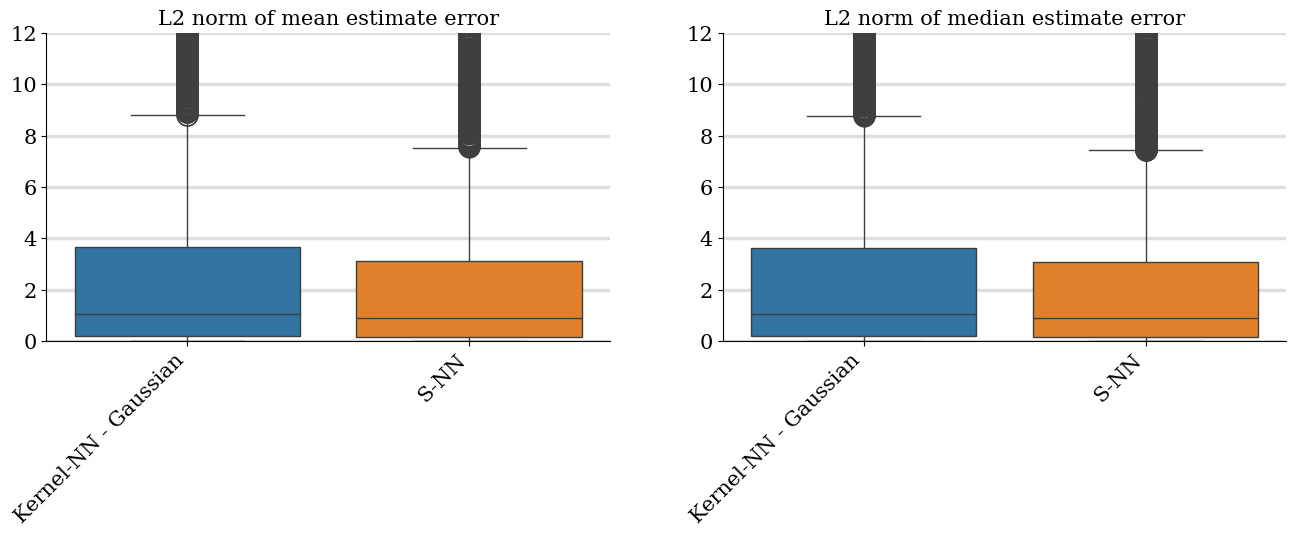

In [393]:
#ax = plt.gca()

fig, (ax1, ax2) = plt.subplots(figsize = (16, 4), ncols = 2)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)

ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.4)


labels = ["Kernel-NN - Gaussian", "S-NN"]
print(mean_plots.T)
sns.boxplot(mean_plots.T, ax = ax1)
sns.boxplot(median_plots.T, ax = ax2)
ax1.set_ylim([0, 12])
ax2.set_ylim([0, 12])
# ax1.set_xlim([0, 5])
# ax2.set_xlim([0, 5])
# ax1.legend(labels = labels)
# ax2.legend(labels = labels)
ax1.set_xticklabels(labels, rotation = 45, ha = 'right')
ax2.set_xticklabels(labels, rotation = 45, ha = 'right')

# ax1.annotate('Outliers above', xy=(-0.3, 20), xytext=(-0.3, 15),
#              arrowprops=dict(facecolor='black', shrink=0.05),
#              )
# ax2.annotate('Outliers above', xy=(-0.3, 20), xytext=(-0.3, 15),
#   arrowprops=dict(facecolor='black', shrink=0.05),
#   )
ax1.set_title("L2 norm of mean estimate error")
ax2.set_title("L2 norm of median estimate error")

#ax1.set_ylabel("L2 error")

plt.savefig("d1_gauss_bigmean_median_boxplot_expkern.pdf", bbox_inches = "tight")

## RDA Sims

In [155]:
# load data
# set up
A_hs = np.load("../data_checkpoints/heartsteps_mask.npy")
M_hs = np.load("../data_checkpoints/heartsteps_data.npy")

M_hs_unsorted = M_hs.copy()

# required for Wasserstein
M_hs = np.sort(M_hs, axis = -1)

# dimension of the data is 1
M_hs = M_hs[:, :, :, None]

# truncate the data as most users have had 40 days
M_hs = M_hs[:, 0:200]
A_hs = A_hs[:, 0:200]

N, T, n, d = M_hs.shape

M = A_hs.copy()
Z = np.log(M_hs.copy() + 1)

In [157]:
dists = dnn.get_col_differences(Z, M, metric = "mmd", kernel = "square")

In [162]:
nonan_dists = dists[~np.isnan(dists)]
np.max(nonan_dists[~np.isinf(nonan_dists)])

np.float64(2013.8339719288417)

In [163]:
# for each row, search for eta, estimate the row

# this time, use even odd split instead of halves

# split_A = np.split(M, 2, axis = 1)
# split_M = np.split(Z, 2, axis = 1)

width = len(M[0])
#ws2_estimates = np.full([N, T, n], np.nan)

#mmd_estimates_exp = [None] * N
mmd_estimates_sq = [None] * N

#nn_ws2 = np.full([N, T], np.nan)
#nn_mmd_exp = np.full([N, T], np.nan)
nn_mmd_sq = np.full([N, T], np.nan)

eta_stars = np.full([N, 6], np.nan)

#neighbors_ws2 = [None] * N

#neighbors_mmd_exp = [None] * N

neighbors_mmd_sq = [None] * N

all_trials = np.full([N, 6], None, dtype = object)

for i in range(len(M)):
  print("User " + str(i))
  # sample split
  dist_A = M.copy()
  dist_A[i] = 0

  #wasserstein_diffs = dnn.get_col_differences(Z, dist_A, metric = "wasserstein2", kernel = None)
  #mmd_exp_diffs = dnn.get_col_differences(Z, dist_A, metric = "mmd", kernel = "exponential")
  mmd_sq_diffs = dnn.get_col_differences(Z, dist_A, metric = "mmd", kernel = "square")


  # s_ws2 = np.split(wasserstein_diffs, 2, axis = 0)
  # diffs_ws2_front = np.split(s_ws2[0], 2, axis = 1)[0]
  # diffs_ws2_back = np.split(s_ws2[1], 2, axis = 1)[1]

  #diffs_ws2_even = wasserstein_diffs[0::2, 0::2]
  #diffs_ws2_odd = wasserstein_diffs[1::2, 1::2]

  # s_mmd_exp = np.split(mmd_exp_diffs, 2, axis = 0)
  # diffs_mmd_exp_front = np.split(s_mmd_exp[0], 2, axis = 1)[0]
  # diffs_mmd_exp_back = np.split(s_mmd_exp[1], 2, axis = 1)[1]

  #diffs_mmd_exp_even = mmd_exp_diffs[0::2, 0::2]
  #diffs_mmd_exp_odd = mmd_exp_diffs[1::2, 1::2]


  # s_mmd_sq = np.split(mmd_sq_diffs, 2, axis = 0)
  # diffs_mmd_sq_front = np.split(s_mmd_sq[0], 2, axis = 1)[0]
  # diffs_mmd_sq_back = np.split(s_mmd_sq[1], 2, axis = 1)[1]

  diffs_mmd_sq_even = mmd_sq_diffs[0::2, 0::2]
  diffs_mmd_sq_odd = mmd_sq_diffs[1::2, 1::2]


  
  # TWO eta searches per row, one using even cols
  # the other using odd cols 

  even_M = M[:,0::2]
  odd_M = M[:,1::2]
  even_Z = Z[:, 0::2]
  odd_Z = Z[:, 1::2]
  

  # eta_star_ws2_even, tr_ws2_even = cv_dnn.search_eta(even_Z, even_M, 5, i, 
  #                                        diffs_ws2_even, dnn.estimate_row, 
  #                                        metric="wasserstein2", 
  #                                        range_min = 0, range_max = 50)
  # eta_stars[i, 0] = eta_star_ws2_even
  # all_trials[i, 0] = tr_ws2_even

  # eta_star_ws2_odd, tr_ws2_odd = cv_dnn.search_eta(odd_Z, odd_M, 5, i,
  #                                       diffs_ws2_odd, dnn.estimate_row,
  #                                       metric = "wasserstein2",
  #                                       range_min = 0, range_max = 50)
  # eta_stars[i, 1] = eta_star_ws2_odd
  # all_trials[i, 1] = tr_ws2_odd
  # eta_star_mmd_exp_even, tr_mmd_exp_even = cv_dnn.search_eta(even_Z, even_M, 5, i, 
  #                                        diffs_mmd_exp_even, dnn.estimate_row, 
  #                                        metric="mmd", kernel = "exponential", 
  #                                        range_min = 0, range_max = 1.9)
  # eta_stars[i, 2] = eta_star_mmd_exp_even
  # all_trials[i, 2] = tr_mmd_exp_even
  # eta_star_mmd_exp_odd, tr_mmd_exp_odd = cv_dnn.search_eta(odd_Z, odd_M, 5, i,
  #                                       diffs_mmd_exp_odd, dnn.estimate_row,
  #                                       metric = "mmd", kernel = "exponential",
  #                                       range_min = 0, range_max = 1.9)
  # all_trials[i, 3] = tr_mmd_exp_odd
  # eta_stars[i, 3] = eta_star_mmd_exp_odd
  eta_star_mmd_sq_even, tr_mmd_sq_even = cv_dnn.search_eta(even_Z, even_M, 5, i, 
                                         diffs_mmd_sq_even, dnn.estimate_row, 
                                         metric="mmd", kernel = "square", 
                                         range_min = 0, range_max = 2100)
  eta_stars[i, 4] = eta_star_mmd_sq_even
  all_trials[i, 4] = tr_mmd_sq_even
  eta_star_mmd_sq_odd, tr_mmd_sq_odd = cv_dnn.search_eta(odd_Z, odd_M, 5, i,
                                        diffs_mmd_sq_odd, dnn.estimate_row,
                                        metric = "mmd", kernel = "square",
                                        range_min = 0, range_max = 2100)
  eta_stars[i, 5] = eta_star_mmd_sq_odd
  all_trials[i, 5] = tr_mmd_sq_odd

  test_inds = np.nonzero(M[i] == 1)[0]
  even_test_inds = test_inds[(test_inds % 2) == 0]
  odd_test_inds = test_inds[(test_inds % 2) != 0]

  print("Estimating unit " + str(i))

  # estimate_even_ws2, nn_even_ws2, neighbors_even_ws2 = dnn.estimate_row(Z, M, i, even_test_inds, 
  #                                       wasserstein_diffs, eta_star_ws2_odd, 
  #                                       "wasserstein2", ret_nn = True)
  # estimate_even_ws2 = estimate_even_ws2[0::2]
  # nn_even_ws2 = nn_even_ws2[0::2]
  # neighbors_even_ws2 = neighbors_even_ws2[0::2]

  # estimate_odd_ws2, nn_odd_ws2, neighbors_odd_ws2 = dnn.estimate_row(Z, M, i, odd_test_inds, 
  #                                       wasserstein_diffs, eta_star_ws2_even, 
  #                                       "wasserstein2", ret_nn = True)
  # estimate_odd_ws2 = estimate_odd_ws2[1::2]
  # nn_odd_ws2 = nn_odd_ws2[1::2]
  # neighbors_odd_ws2 = neighbors_odd_ws2[1::2]

  # estimate_even_mmd_exp, nn_even_mmd_exp, neighbors_even_mmd_exp = dnn.estimate_row(Z, M, i, even_test_inds,
  #                                           mmd_exp_diffs, eta_star_mmd_exp_odd,
  #                                           "mmd", ret_nn = True)
  # estimate_even_mmd_exp = estimate_even_mmd_exp[0::2]
  # nn_even_mmd_exp = nn_even_mmd_exp[0::2]
  # neighbors_even_mmd_exp = neighbors_even_mmd_exp[0::2]

  # estimate_odd_mmd_exp, nn_odd_mmd_exp, neighbors_odd_mmd_exp = dnn.estimate_row(Z, M, i, odd_test_inds,
  #                                           mmd_exp_diffs, eta_star_mmd_exp_even,
  #                                           "mmd", ret_nn = True)
  # estimate_odd_mmd_exp = estimate_odd_mmd_exp[1::2]
  # nn_odd_mmd_exp = nn_odd_mmd_exp[1::2]
  # neighbors_odd_mmd_exp = neighbors_odd_mmd_exp[1::2]

  estimate_even_mmd_sq, nn_even_mmd_sq, neighbors_even_mmd_sq = dnn.estimate_row(Z, M, i, even_test_inds,
                                            mmd_sq_diffs, eta_star_mmd_sq_odd,
                                            "mmd", ret_nn = True)
  estimate_even_mmd_sq = estimate_even_mmd_sq[0::2]
  nn_even_mmd_sq = nn_even_mmd_sq[0::2]
  neighbors_even_mmd_sq = neighbors_even_mmd_sq[0::2]

  estimate_odd_mmd_sq, nn_odd_mmd_sq, neighbors_odd_mmd_sq = dnn.estimate_row(Z, M, i, odd_test_inds,
                                            mmd_sq_diffs, eta_star_mmd_sq_even,
                                            "mmd", ret_nn = True)
  estimate_odd_mmd_sq = estimate_odd_mmd_sq[1::2]
  nn_odd_mmd_sq = nn_odd_mmd_sq[1::2]
  neighbors_odd_mmd_sq = neighbors_odd_mmd_sq[1::2]
  
  # splice estimates together
  # est_row_ws2 = np.full([T, n], np.nan)
  # est_row_ws2[0::2] = estimate_even_ws2
  # est_row_ws2[1::2] = estimate_odd_ws2

  # est_row_mmd_exp = [None] * T
  # est_row_mmd_exp[0::2] = estimate_even_mmd_exp
  # est_row_mmd_exp[1::2] = estimate_odd_mmd_exp

  est_row_mmd_sq = [None] * T
  est_row_mmd_sq[0::2] = estimate_even_mmd_sq
  est_row_mmd_sq[1::2] = estimate_odd_mmd_sq

  # row_nn_ws2 = np.full(T, np.nan)
  # row_nn_ws2[0::2] = nn_even_ws2
  # row_nn_ws2[1::2] = nn_odd_ws2

  # row_nn_mmd_exp = np.full(T, np.nan)
  # row_nn_mmd_exp[0::2] = nn_even_mmd_exp
  # row_nn_mmd_exp[1::2] = nn_odd_mmd_exp

  row_nn_mmd_sq = np.full(T, np.nan)
  row_nn_mmd_sq[0::2] = nn_even_mmd_sq
  row_nn_mmd_sq[1::2] = nn_odd_mmd_sq

  # row_neighbors_ws2 = [None] * T
  # row_neighbors_ws2[0::2] = neighbors_even_ws2
  # row_neighbors_ws2[1::2] = neighbors_odd_ws2

  # row_neighbors_mmd_exp = [None] * T
  # row_neighbors_mmd_exp[0::2] = neighbors_even_mmd_exp
  # row_neighbors_mmd_exp[1::2] = neighbors_odd_mmd_exp

  row_neighbors_mmd_sq = [None] * T
  row_neighbors_mmd_sq[0::2] = neighbors_even_mmd_sq
  row_neighbors_mmd_sq[1::2] = neighbors_odd_mmd_sq

  # est_row_ws2 = np.concatenate((estimate_front_ws2, estimate_back_ws2), axis = 0)
  # est_row_mmd_exp = estimate_front_mmd_exp + estimate_back_mmd_exp
  # est_row_mmd_sq = estimate_front_mmd_sq + estimate_back_mmd_sq

  # row_nn_ws2 = np.concatenate((nn_front_ws2, nn_back_ws2), axis = 0)
  # row_nn_mmd_exp = np.concatenate((nn_front_mmd_exp, nn_back_mmd_exp), axis = 0)
  # row_nn_mmd_sq = np.concatenate((nn_front_mmd_sq, nn_back_mmd_sq), axis = 0)

  # row_neighbors_ws2 = neighbors_front_ws2 + neighbors_back_ws2
  # row_neighbors_mmd_exp = neighbors_front_mmd_exp + neighbors_back_mmd_exp
  # row_neighbors_mmd_sq = neighbors_front_mmd_sq + neighbors_back_mmd_sq

  # neighbors_ws2[i] = row_neighbors_ws2
  # neighbors_mmd_exp[i] = row_neighbors_mmd_exp
  neighbors_mmd_sq[i] = row_neighbors_mmd_sq

  # ws2_estimates[i] = est_row_ws2
  # mmd_estimates_exp[i] = est_row_mmd_exp
  mmd_estimates_sq[i] = est_row_mmd_sq

  # nn_ws2[i] = row_nn_ws2
  # nn_mmd_exp[i] = row_nn_mmd_exp
  nn_mmd_sq[i] = row_nn_mmd_sq

User 0


c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\dnn.py:133: RuntimeWarning: Mean of empty slice
  val = np.nanmean(val_all)


 20%|█▉        | 39/200 [00:00<00:02, 65.15trial/s, best loss: 68.44078909603255]

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\dnn.py:46: RuntimeWarning: invalid value encountered in matmul
  XY = np.matmul(dat1, np.transpose(dat2))  # m by n matrix with x_i^Ty_j

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\dnn.py:67: RuntimeWarning: invalid value encountered in scalar subtract
  (np.sum(kXX) - np.sum(np.diag(kXX))) / (m * (m - 1))



100%|██████████| 200/200 [00:02<00:00, 90.85trial/s, best loss: 47.64327821440632]
Estimating unit 0
User 1
100%|██████████| 200/200 [00:01<00:00, 115.05trial/s, best loss: 24.01497909142016]
Estimating unit 1
User 2
100%|██████████| 200/200 [00:01<00:00, 104.97trial/s, best loss: 8.062976615373021]
Estimating unit 2
User 3
100%|██████████| 200/200 [00:01<00:00, 108.27trial/s, best loss: 94.51746802434033]
Estimating unit 3
User 4
100%|██████████| 200/200 [00:02<00:00, 93.28trial/s, best loss: 40.6845892167066] 
Estimating unit 4
User 5
100%|██████████| 200/200 [00:01<00:00, 115.89trial/s, best loss: 52.82904931524756]
Estimating unit 5
User 6
100%|██████████| 200/200 [00:02<00:00, 86.17trial/s, best loss: 40.967063908321826]
Estimating unit 6
User 7
100%|██████████| 200/200 [00:02<00:00, 95.36trial/s, best loss: 12.33487358086733] 
Estimating unit 7
User 8
100%|██████████| 200/200 [00:02<00:00, 92.75trial/s, best loss: 29.419168930956694]
Estimating unit 8
User 9
100%|██████████| 200/

In [164]:
Z_mean = np.nanmean(Z, axis = -2)
Z_std = np.nanstd(Z, axis = -2)
Z_var = np.nanvar(Z, axis = -2)
Z_max = np.nanmax(Z, axis = -2)
Z_median = np.nanmedian(Z, axis = -2)

C:\Users\Caleb\AppData\Local\Temp\ipykernel_23928\3781569590.py:1: RuntimeWarning: Mean of empty slice
  Z_mean = np.nanmean(Z, axis = -2)
c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:2035: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
C:\Users\Caleb\AppData\Local\Temp\ipykernel_23928\3781569590.py:3: RuntimeWarning: Degrees of freedom <= 0 for slice.
  Z_var = np.nanvar(Z, axis = -2)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_23928\3781569590.py:4: RuntimeWarning: All-NaN slice encountered
  Z_max = np.nanmax(Z, axis = -2)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_23928\3781569590.py:5: RuntimeWarning: All-NaN slice encountered
  Z_median = np.nanmedian(Z, axis = -2)


In [175]:
dists = scaler_methods.all_dissims(Z_max, M, ax = 1)


# mean 0 to 20
# std 0 to 8
# var 0 to 57
# median 0 to 36
# max 0 to 40


c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\scaler_methods.py:198: RuntimeWarning: Mean of empty slice
  mean_row_dis = np.nanmean(dis, axis = 2)


In [176]:
nonan_dists = dists[~np.isnan(dists)]
np.max(nonan_dists[~np.isinf(nonan_dists)])

np.float64(39.13440858489725)

In [177]:
# snn estimates
# for each row, search for eta, estimate the row
# this time, split by users rather than time
split_A = np.split(M, 2, axis = 1)

split_M_mean = np.split(Z_mean, 2, axis = 1)
split_M_std = np.split(Z_std, 2, axis = 1)
split_M_var = np.split(Z_var, 2, axis = 1)
split_M_max = np.split(Z_max, 2, axis = 1)
split_M_median = np.split(Z_median, 2, axis = 1)

width = len(M[0])

snn_mean_estimates = np.full([N, T, d], np.nan)
snn_std_estimates = np.full([N, T, d], np.nan)
snn_var_estimates = np.full([N, T, d], np.nan)
snn_max_estimates = np.full([N, T, d], np.nan)
snn_median_estimates = np.full([N, T, d], np.nan)

#ws2_estimates = np.full([N, T, n], np.nan)

#mmd_estimates_exp = [None] * N
#mmd_estimates_sq = [None] * N

#nn_ws2 = np.full([N, T], np.nan)
#nn_mmd_exp = np.full([N, T], np.nan)
#nn_mmd_sq = np.full([N, T], np.nan)

#eta_stars = np.full([37, 6], np.nan)

#neighbors_ws2 = [None] * N

#neighbors_mmd_exp = [None] * N

#neighbors_mmd_sq = [None] * N

for i in range(len(M)):
  print("User " + str(i))
  # sample split
  dist_A = M.copy()
  dist_A[i] = 0

  # wasserstein_diffs = dnn.get_col_differences(Z, dist_A, metric = "wasserstein2", kernel = None)
  # mmd_exp_diffs = dnn.get_col_differences(Z, dist_A, metric = "mmd", kernel = "exponential")
  # mmd_sq_diffs = dnn.get_col_differences(Z, dist_A, metric = "mmd", kernel = "square")

  snn_mean_dissims = scaler_methods.all_dissims(Z_mean, dist_A, ax = 1)
  snn_std_dissims = scaler_methods.all_dissims(Z_std, dist_A, ax = 1)
  snn_var_dissims = scaler_methods.all_dissims(Z_var, dist_A, ax = 1)
  snn_max_dissims = scaler_methods.all_dissims(Z_max, dist_A, ax = 1)
  snn_median_dissims = scaler_methods.all_dissims(Z_median, dist_A, ax = 1)

  diffs_snn_even_mean = snn_mean_dissims[0::2, 0::2]
  diffs_snn_even_std = snn_std_dissims[0::2, 0::2]
  diffs_snn_even_var = snn_var_dissims[0::2, 0::2]
  diffs_snn_even_median = snn_median_dissims[0::2, 0::2]
  diffs_snn_even_max = snn_max_dissims[0::2, 0::2]

  diffs_snn_odd_mean = snn_mean_dissims[1::2, 1::2]
  diffs_snn_odd_std = snn_std_dissims[1::2, 1::2]
  diffs_snn_odd_var = snn_var_dissims[1::2, 1::2]
  diffs_snn_odd_median = snn_median_dissims[1::2, 1::2]
  diffs_snn_odd_max = snn_max_dissims[1::2, 1::2]
  
  # s_snn_mean = np.split(snn_mean_dissims, 2, axis = 0)
  # s_snn_std = np.split(snn_std_dissims, 2, axis = 0)
  # s_snn_var = np.split(snn_var_dissims, 2, axis = 0)
  # s_snn_max = np.split(snn_max_dissims, 2, axis = 0)
  # s_snn_median = np.split(snn_median_dissims, 2, axis = 0)
  
  # diffs_snn_front_mean = np.split(s_snn_mean[0], 2, axis = 1)[0]
  # diffs_snn_back_mean = np.split(s_snn_mean[1], 2, axis = 1)[1]
  
  # diffs_snn_front_std = np.split(s_snn_std[0], 2, axis = 1)[0]
  # diffs_snn_back_std = np.split(s_snn_std[1], 2, axis = 1)[1]

  # diffs_snn_front_var = np.split(s_snn_var[0], 2, axis = 1)[0]
  # diffs_snn_back_var = np.split(s_snn_var[1], 2, axis = 1)[1]

  # diffs_snn_front_max = np.split(s_snn_max[0], 2, axis = 1)[0]
  # diffs_snn_back_max = np.split(s_snn_max[1], 2, axis = 1)[1]

  # diffs_snn_front_median = np.split(s_snn_median[0], 2, axis = 1)[0]
  # diffs_snn_back_median = np.split(s_snn_median[1], 2, axis = 1)[1]


  # s_mmd_exp = np.split(mmd_exp_diffs, 2, axis = 0)
  # diffs_mmd_exp_front = np.split(s_mmd_exp[0], 2, axis = 1)[0]
  # diffs_mmd_exp_back = np.split(s_mmd_exp[1], 2, axis = 1)[1]

  # s_mmd_sq = np.split(mmd_sq_diffs, 2, axis = 0)
  # diffs_mmd_sq_front = np.split(s_mmd_sq[0], 2, axis = 1)[0]
  # diffs_mmd_sq_back = np.split(s_mmd_sq[1], 2, axis = 1)[1]

  
  # TWO eta searches per row, one using the front half
  # the other using the back half 

  # front_M = split_A[0]
  # back_M = split_A[1]

  # front_Z_mean = split_M_mean[0]
  # back_Z_mean = split_M_mean[1]
  # front_Z_std = split_M_std[0]
  # back_Z_std = split_M_std[1]
  # front_Z_var = split_M_var[0]
  # back_Z_var = split_M_var[1]
  # front_Z_max = split_M_max[0]
  # back_Z_max = split_M_max[1]
  # front_Z_median = split_M_median[0]
  # back_Z_median = split_M_median[1]

  even_Z_mean = Z_mean[:, 0::2]
  odd_Z_mean = Z_mean[:, 1::2]
  even_Z_std = Z_std[:, 0::2]
  odd_Z_std = Z_std[:, 1::2]
  even_Z_var = Z_var[:, 0::2]
  odd_Z_var = Z_var[:, 1::2]
  even_Z_median = Z_median[:, 0::2]
  odd_Z_median = Z_median[:, 1::2]
  even_Z_max = Z_max[:, 0::2]
  odd_Z_max = Z_max[:, 1::2]

  even_M = M[:, 0::2]
  odd_M = M[:, 1::2]

  print(diffs_snn_even_mean.shape)
  # mean 0-150000
# std 0-51000
# var 0-2000000000
# max 0-450000
# median 0-170000
  
# mean 0 to 1.5
# std 0 to 1
# var 0 to 15
# median 0 to 1.5
# max 0 to 3

# mean 0 to 1
# std 0 to 0.3
# var 0 to 3
# median 0 to 1
# max 0 to 1

# mean 0 to 2
# std 0 to 1
# var 0 to 55
# median 0 to 2
# max 0 to 3.5

# mean 0 to 20
# std 0 to 8
# var 0 to 57
# median 0 to 36
# max 0 to 40
  eta_star_snn_even_mean, _ = scaler_methods.search_eta(even_Z_mean, even_M, 5, i, 
                                         diffs_snn_even_mean, range_min = 0, range_max = 20)

  eta_star_snn_odd_mean, _ = scaler_methods.search_eta(odd_Z_mean, odd_M, 5, i,
                                        diffs_snn_odd_mean, range_min = 0, range_max = 20)
  
  eta_star_snn_even_std, _ = scaler_methods.search_eta(even_Z_std, even_M, 5, i, 
                                         diffs_snn_even_std, range_min = 0, range_max = 8)

  eta_star_snn_odd_std, _ = scaler_methods.search_eta(odd_Z_std, odd_M, 5, i,
                                        diffs_snn_odd_std, range_min = 0, range_max = 8)
  
  eta_star_snn_even_var, _ = scaler_methods.search_eta(even_Z_var, even_M, 5, i, 
                                         diffs_snn_even_var, range_min = 0, range_max = 57)

  eta_star_snn_odd_var, _ = scaler_methods.search_eta(odd_Z_var, odd_M, 5, i,
                                        diffs_snn_odd_var, range_min = 0, range_max = 57)
  
  eta_star_snn_even_median, _ = scaler_methods.search_eta(even_Z_median, even_M, 5, i, 
                                         diffs_snn_even_median, range_min = 0, range_max = 36)

  eta_star_snn_odd_median, _ = scaler_methods.search_eta(odd_Z_median, odd_M, 5, i,
                                        diffs_snn_odd_median, range_min = 0, range_max = 36)
  
  eta_star_snn_even_max, _ = scaler_methods.search_eta(even_Z_max, even_M, 5, i, 
                                         diffs_snn_even_max, range_min = 0, range_max = 40)

  eta_star_snn_odd_max, _ = scaler_methods.search_eta(odd_Z_max, odd_M, 5, i,
                                        diffs_snn_odd_max, range_min = 0, range_max = 40)

  # eta_star_snn_front_std, _ = scaler_methods.search_eta(front_Z_std, front_M, 5, i, 
  #                                        diffs_snn_front_std, range_min = 0, range_max = 51000)

  # eta_star_snn_back_std, _ = scaler_methods.search_eta(back_Z_std, back_M, 5, i,
  #                                       diffs_snn_back_std, range_min = 0, range_max = 51000)

  # eta_star_snn_front_var, _ = scaler_methods.search_eta(front_Z_var, front_M, 5, i, 
  #                                        diffs_snn_front_var, range_min = 0, range_max = 2000000000)

  # eta_star_snn_back_var, _ = scaler_methods.search_eta(back_Z_var, back_M, 5, i,
  #                                       diffs_snn_back_var, range_min = 0, range_max = 2000000000)

  # eta_star_snn_front_max, _ = scaler_methods.search_eta(front_Z_max, front_M, 5, i,
  #                                       diffs_snn_front_max, range_min = 0, range_max = 450000)

  # eta_star_snn_back_max, _ = scaler_methods.search_eta(back_Z_max, back_M, 5, i,
  #                                       diffs_snn_back_max, range_min = 0, range_max = 450000)
  
  # eta_star_snn_front_median, _ = scaler_methods.search_eta(front_Z_median, front_M, 5, i,
  #                                       diffs_snn_front_median, range_min = 0, range_max = 170000)

  # eta_star_snn_back_median, _ = scaler_methods.search_eta(back_Z_median, back_M, 5, i,
  #                                       diffs_snn_back_median, range_min = 0, range_max = 170000)


  # estimate first half using eta from second
  test_inds = np.nonzero(M[i] == 1)[0]
  # front_test_inds = test_inds[test_inds < (width / 2)]
  # back_test_inds = test_inds[test_inds >= (width / 2)]
  even_test_inds = test_inds[(test_inds % 2) == 0]
  odd_test_inds = test_inds[(test_inds % 2) != 0]


  print("Estimating unit " + str(i))

  estimate_even_snn_mean = scaler_methods.estimate_row(Z_mean, M, i, even_test_inds, 
                                        snn_mean_dissims, eta_star_snn_odd_mean, ax = 1)

  estimate_even_snn_mean = estimate_even_snn_mean[0::2]

  estimate_odd_snn_mean = scaler_methods.estimate_row(Z_mean, M, i, odd_test_inds, 
                                          snn_mean_dissims, eta_star_snn_even_mean, ax = 1)
  estimate_odd_snn_mean = estimate_odd_snn_mean[1::2]

  # std
  estimate_even_snn_std = scaler_methods.estimate_row(Z_std, M, i, even_test_inds, 
                                        snn_std_dissims, eta_star_snn_odd_std, ax = 1)

  estimate_even_snn_std = estimate_even_snn_std[0::2]

  estimate_odd_snn_std = scaler_methods.estimate_row(Z_std, M, i, odd_test_inds, 
                                          snn_std_dissims, eta_star_snn_even_std, ax = 1)
  estimate_odd_snn_std = estimate_odd_snn_std[1::2]
  # var
  estimate_even_snn_var = scaler_methods.estimate_row(Z_var, M, i, even_test_inds, 
                                        snn_var_dissims, eta_star_snn_odd_var, ax = 1)

  estimate_even_snn_var = estimate_even_snn_var[0::2]

  estimate_odd_snn_var = scaler_methods.estimate_row(Z_var, M, i, odd_test_inds, 
                                          snn_var_dissims, eta_star_snn_even_var, ax = 1)
  estimate_odd_snn_var = estimate_odd_snn_var[1::2]

  # median
  estimate_even_snn_median = scaler_methods.estimate_row(Z_median, M, i, even_test_inds, 
                                        snn_median_dissims, eta_star_snn_odd_median, ax = 1)

  estimate_even_snn_median = estimate_even_snn_median[0::2]

  estimate_odd_snn_median = scaler_methods.estimate_row(Z_median, M, i, odd_test_inds, 
                                          snn_median_dissims, eta_star_snn_even_median, ax = 1)
  estimate_odd_snn_median = estimate_odd_snn_median[1::2]

  # max
  estimate_even_snn_max = scaler_methods.estimate_row(Z_max, M, i, even_test_inds, 
                                        snn_max_dissims, eta_star_snn_odd_max, ax = 1)

  estimate_even_snn_max = estimate_even_snn_max[0::2]

  estimate_odd_snn_max = scaler_methods.estimate_row(Z_max, M, i, odd_test_inds, 
                                          snn_max_dissims, eta_star_snn_even_max, ax = 1)
  estimate_odd_snn_max = estimate_odd_snn_max[1::2]



  
  # concat estimates together
  est_row_snn_mean = np.full([T, d], np.nan)
  est_row_snn_mean[0::2] = estimate_even_snn_mean
  est_row_snn_mean[1::2] = estimate_odd_snn_mean

  est_row_snn_std = np.full([T, d], np.nan)
  est_row_snn_std[0::2] = estimate_even_snn_std
  est_row_snn_std[1::2] = estimate_odd_snn_std

  est_row_snn_var = np.full([T, d], np.nan)
  est_row_snn_var[0::2] = estimate_even_snn_var
  est_row_snn_var[1::2] = estimate_odd_snn_var

  est_row_snn_median = np.full([T, d], np.nan)
  est_row_snn_median[0::2] = estimate_even_snn_median
  est_row_snn_median[1::2] = estimate_odd_snn_median

  est_row_snn_max = np.full([T, d], np.nan)
  est_row_snn_max[0::2] = estimate_even_snn_max
  est_row_snn_max[1::2] = estimate_odd_snn_max
  # est_row_snn_mean = np.concatenate((estimate_even_snn_mean, estimate_odd_snn_mean), axis = 0)
  # est_row_snn_std = np.concatenate((estimate_even_snn_std, estimate_odd_snn_std), axis = 0)
  # est_row_snn_var = np.concatenate((estimate_even_snn_var, estimate_odd_snn_var), axis = 0)
  # est_row_snn_max = np.concatenate((estimate_even_snn_max, estimate_odd_snn_max), axis = 0)
  # est_row_snn_median = np.concatenate((estimate_even_snn_median, estimate_odd_snn_median), axis = 0)


  snn_mean_estimates[i] = est_row_snn_mean
  snn_std_estimates[i] = est_row_snn_std
  snn_var_estimates[i] = est_row_snn_var
  snn_max_estimates[i] = est_row_snn_max
  snn_median_estimates[i] = est_row_snn_median


User 0
(100, 100)
100%|██████████| 200/200 [00:00<00:00, 232.40trial/s, best loss: 5.3575124410864]
Estimating unit 0
User 1
(100, 100)
100%|██████████| 200/200 [00:00<00:00, 233.48trial/s, best loss: 3.419868225654305]
Estimating unit 1
User 2
(100, 100)
100%|██████████| 200/200 [00:00<00:00, 214.33trial/s, best loss: 6.577199372991562]
Estimating unit 2
User 3
(100, 100)
100%|██████████| 200/200 [00:00<00:00, 219.48trial/s, best loss: 7.070070105910133]
Estimating unit 3
User 4
(100, 100)
100%|██████████| 200/200 [00:00<00:00, 212.34trial/s, best loss: 5.087809727391028]
Estimating unit 4
User 5
(100, 100)
100%|██████████| 200/200 [00:00<00:00, 207.63trial/s, best loss: 0.7040219302572701]
Estimating unit 5
User 6
(100, 100)
100%|██████████| 200/200 [00:00<00:00, 220.67trial/s, best loss: 6.889058128369382]
Estimating unit 6
User 7
(100, 100)
100%|██████████| 200/200 [00:00<00:00, 209.20trial/s, best loss: 1.9710123366428074]
Estimating unit 7
User 8
(100, 100)
100%|██████████| 200/2

In [178]:
abs_error_snn_mean = abs(Z_mean - snn_mean_estimates)
abs_error_snn_std = abs(Z_std - snn_std_estimates)
abs_error_snn_var = abs(Z_var - snn_var_estimates)
abs_error_snn_max = abs(Z_max - snn_max_estimates)
abs_error_snn_median = abs(Z_median - snn_median_estimates)

In [179]:
nans = 0
mmd_sq_mean = np.full([N, T, d], np.nan)
mmd_sq_std = np.full([N, T, d], np.nan)
mmd_sq_var = np.full([N, T, d], np.nan)
mmd_sq_max = np.full([N, T, d], np.nan)
mmd_sq_median = np.full([N, T, d], np.nan)
for i in range(N):
  for j in range(T):
    if mmd_estimates_sq[i][j] is None:
      continue
    mmd_sq_mean[i, j] = np.nanmean(mmd_estimates_sq[i][j], axis = 0)
    mmd_sq_std[i, j] = np.nanstd(mmd_estimates_sq[i][j], axis = 0)
    mmd_sq_var[i, j] = np.nanvar(mmd_estimates_sq[i][j], axis = 0)
    mmd_sq_max[i, j] = np.nanmax(mmd_estimates_sq[i][j], axis = 0)
    mmd_sq_median[i, j] = np.nanmedian(mmd_estimates_sq[i][j], axis = 0)

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1882: RuntimeWarning: invalid value encountered in subtract
  np.subtract(arr, avg, out=arr, casting='unsafe', where=where)


In [180]:
abs_error_mmdsq_mean = abs(Z_mean - mmd_sq_mean)
abs_error_mmdsq_std = abs(Z_std - mmd_sq_std)
abs_error_mmdsq_var = abs(Z_mean - mmd_sq_var)
abs_error_mmdsq_median = abs(Z_mean - mmd_sq_median)
abs_error_mmdsq_max = abs(Z_mean - mmd_sq_max)

In [183]:
# all neighbors
mean_plots = np.array([abs_error_mmdsq_mean.flatten(), abs_error_snn_mean.flatten()])
std_plots = np.array([abs_error_mmdsq_std.flatten(), abs_error_snn_std.flatten()])
var_plots = np.array([abs_error_mmdsq_var.flatten(), abs_error_snn_var.flatten()])
median_plots = np.array([abs_error_mmdsq_median.flatten(), abs_error_snn_median.flatten()])
max_plots = np.array([abs_error_mmdsq_max.flatten(), abs_error_snn_max.flatten()])


C:\Users\Caleb\AppData\Local\Temp\ipykernel_23928\4066076322.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(labels, rotation = 45, ha = 'right')
C:\Users\Caleb\AppData\Local\Temp\ipykernel_23928\4066076322.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(labels, rotation = 45, ha = 'right')


Text(0.5, 1.0, 'L2 norm of median estimate error')

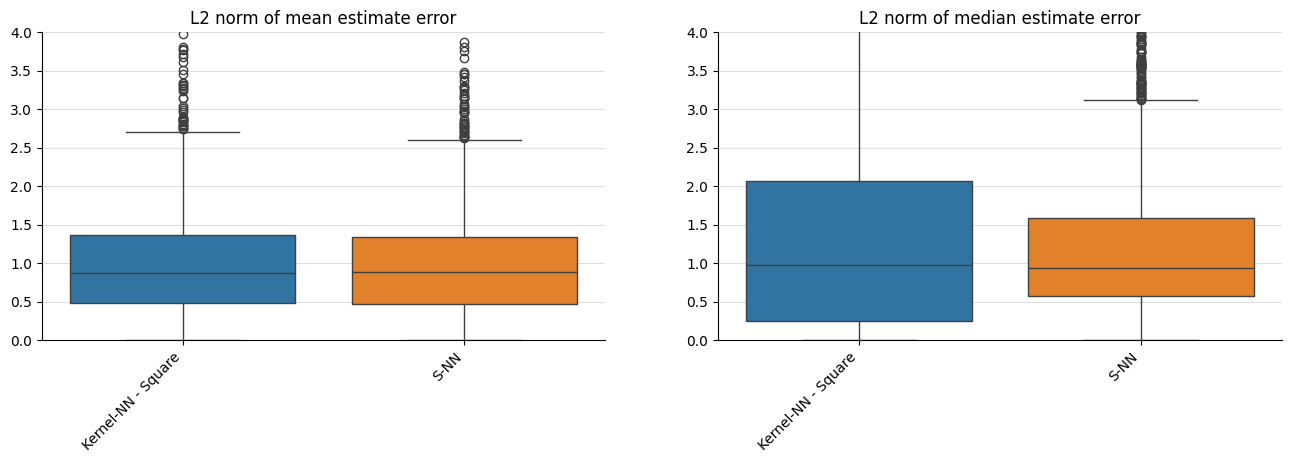

In [189]:
#ax = plt.gca()

fig, (ax1, ax2) = plt.subplots(figsize = (16, 4), ncols = 2)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)

ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.4)


labels = ["Kernel-NN - Square", "S-NN"]
#print(mean_plots.T)
sns.boxplot(mean_plots.T, ax = ax1)
sns.boxplot(median_plots.T, ax = ax2)
ax1.set_ylim([0, 4])
ax2.set_ylim([0, 4])
# ax1.set_xlim([0, 5])
# ax2.set_xlim([0, 5])
# ax1.legend(labels = labels)
# ax2.legend(labels = labels)
ax1.set_xticklabels(labels, rotation = 45, ha = 'right')
ax2.set_xticklabels(labels, rotation = 45, ha = 'right')

# ax1.annotate('Outliers above', xy=(-0.3, 20), xytext=(-0.3, 15),
#              arrowprops=dict(facecolor='black', shrink=0.05),
#              )
# ax2.annotate('Outliers above', xy=(-0.3, 20), xytext=(-0.3, 15),
#   arrowprops=dict(facecolor='black', shrink=0.05),
#   )
ax1.set_title("L2 norm of mean estimate error")
ax2.set_title("L2 norm of median estimate error")

#ax1.set_ylabel("L2 error")

#plt.savefig("d2_mean_median_error.pdf", bbox_inches = "tight")

Text(0.5, 1.0, 'L2 norm of median estimate error')

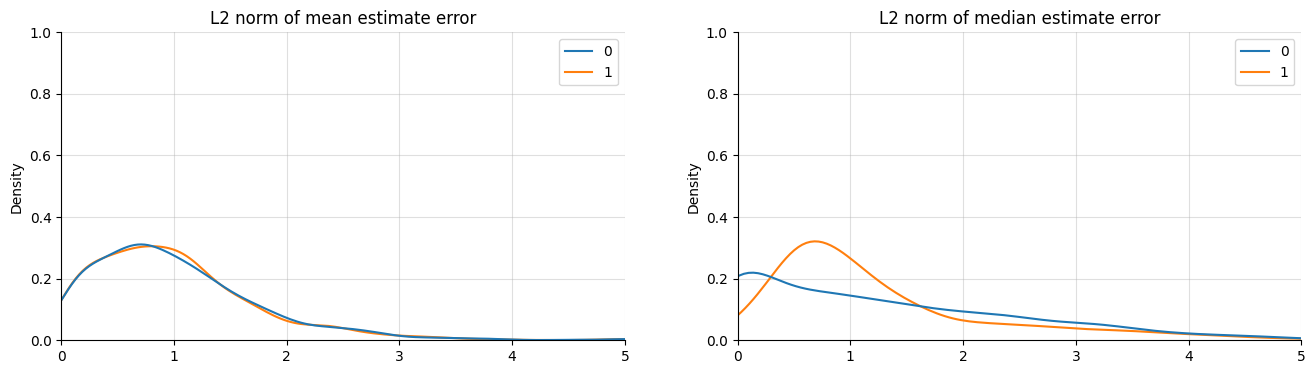

In [192]:
#ax = plt.gca()

fig, (ax1, ax2) = plt.subplots(figsize = (16, 4), ncols = 2)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)

ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.4)


labels = ["Kernel-NN - Square", "S-NN"]
#print(mean_plots.T)
sns.kdeplot(mean_plots.T, ax = ax1)
sns.kdeplot(median_plots.T, ax = ax2)
ax1.set_ylim([0, 1])
ax2.set_ylim([0, 1])
ax1.set_xlim([0, 5])
ax2.set_xlim([0, 5])
#ax1.legend(labels = labels)
#ax2.legend(labels = labels)
#ax1.set_xticklabels(labels, rotation = 45, ha = 'right')
#ax2.set_xticklabels(labels, rotation = 45, ha = 'right')

# ax1.annotate('Outliers above', xy=(-0.3, 20), xytext=(-0.3, 15),
#              arrowprops=dict(facecolor='black', shrink=0.05),
#              )
# ax2.annotate('Outliers above', xy=(-0.3, 20), xytext=(-0.3, 15),
#   arrowprops=dict(facecolor='black', shrink=0.05),
#   )
ax1.set_title("L2 norm of mean estimate error")
ax2.set_title("L2 norm of median estimate error")

#ax1.set_ylabel("L2 error")

#plt.savefig("d2_mean_median_error.pdf", bbox_inches = "tight")

## Vary N sims

In [6]:
from hyperopt import hp
import kernel_nn
from kernel_nn import KernelNN

In [427]:
knn_sims = KernelNN(k = 5, rand_seed = 42)


In [428]:
diffs = knn_sims.distances(M_hs, A_hs)

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\kernel_nn.py:108: RuntimeWarning: Mean of empty slice
  val = np.nanmean(val_all)


In [435]:
len(diffs[~np.isnan(diffs)])

30978

In [74]:
def gendata_rebut(N, T, n, d, eps_N, eps_T, p, missing_pattern, seed) : 
    """ 
    Generates Gaussian data, with latent dimension r = 2

    Note - N, d are both EVEN positive integers

    This is specialized to the case with added missing mechanisms 
        Unobserved confounding to full extent - up to U and V
        Conditional correlation between treatments - up to m-dependence (m = 1 or 2)
    """
    np.random.seed(seed)
    
    ## Data Matrix (N * T * n * d)
    
    Data = np.zeros( (N, T, n, d) )
    true_Mean = np.zeros( (N, T, d) )
    true_Cov = np.zeros( (N, T, d, d) )

    u_1 = np.random.uniform(-1, 1, N)
    u_2 = np.random.uniform(0.2, 1, N)

    v_1 = np.random.uniform(-2, 2, T)
    v_2 = np.random.uniform(0.5, 2, T)

    even_ones = np.repeat([0, 1], d/2)
    odd_ones = np.repeat([1, 0], d/2)

    for i in range(N) : 
        for t in range(T) : 
            m_it = u_1[i]*v_1[t]*(even_ones - odd_ones)
            c_it = np.diag(u_2[i]*v_2[t]*(0.5*even_ones + odd_ones))
            true_Mean[i, t, :] = m_it
            true_Cov[i, t, :, :] = c_it
            dat_mat = np.random.multivariate_normal(m_it, c_it, size = n)
            Data[i, t, :, :] = dat_mat


    ## Masking Matrix (N * T)

    Masking = np.zeros( (N, T) )

    zero_rows = math.floor(N**(1 - eps_N))
    zero_cols = math.floor(T**(1 - eps_T))
    
    expit = lambda x : np.exp(x)/(1 + np.exp(x))

    beta1 = np.repeat((-0.1, 0.2), N/2) # coeff of row latent factor
    beta2 = np.repeat((0.5, -0.1), T/2) # coeff of column latent factor

    if missing_pattern == "mcar" : 
        Masking = np.reshape(np.random.binomial(1, p, (N*T)), (N, T))
    elif missing_pattern == "staggered" : 
        Masking = np.column_stack( (np.row_stack((np.zeros( (zero_rows, zero_cols) ), np.ones( ( (N - zero_rows), zero_cols ) ))), np.row_stack((np.ones( ( zero_rows, (T - zero_cols) ) ), np.ones( ( (N - zero_rows), (T - zero_cols) ) )))) )
    elif missing_pattern == "mnar + uniform" : # Previously "mnar + non-positive"
        beta = np.repeat((-0.1, 0.2), N/2)
        Masking = np.reshape(np.random.binomial( 1, expit(sum(beta * u_1)), (N*T) ), (N, T)) 
    elif missing_pattern == "mnar2"  :# u_i + \beta
        Masking = np.zeros( (N, T) )
        for i in range(N) : 
            Masking[i, :] = np.random.binomial( 1, expit(sum(u_1[i] + u_2[i])), T )
    elif missing_pattern == "mnar2 + full_confounding" : 
        Masking = np.zeros( (N, T) )
        for i in range(N) : 
            for t in range(T) : 
                Masking[i, t] = np.random.binomial( 1, expit( u_1[i] + u_2[i] + v_1[t] + v_2[t] ), 1 )
    elif missing_pattern == "mnar2 + correlated" : 
        Masking = np.zeros( (N, T) )
        corr_mat = tridiag( 0.3*np.ones(T - 1), np.ones(T), 0.3*np.ones(T - 1) )
        for i in range(N) : 
            m_i = expit(u_1[i] + u_2[i])
            print(m_i)
            commonprob = bnd.bincorr2commonprob(margprob = [m_i] * T, bincorr = corr_mat)
            Masking[i, :] = bnd.rmvbin(margprob = np.diag(commonprob), commonprob = commonprob, N = 1)*1
    else:
        raise ValueError("Missing pattern incorrect")
    return(Data, Masking, true_Mean, true_Cov)



In [68]:
Data, Masking, true_Mean, true_Cov = gendata_rebut(2**8, 60, 60, 4, 0.3, 0.3, 0.5, "mnar2 + correlated", seed = 12)


0.48749155826936447
0.7442927729856438
0.5844667732462103
0.5977387877117488
0.4602834212366401
0.7415694554324873
0.7520541308203629
0.34521517977421906
0.7960548069409904


ValueError: The input matrix must be symmetric positive semidefinite.

In [90]:
knn_ss = KernelNN(kernel = "square", nn_type = "uu", k = 5, rand_seed = 42)
knn_ss.set_etaspace(hp.uniform('eta', 0, 100))

In [455]:
dists = knn_ss.distances(Data, Masking)

In [456]:
np.max(Data)

np.float64(5.557574116594009)

In [457]:
np.nanmax(dists[~np.isinf(dists)])

np.float64(78.04916100952693)

In [470]:
knn_ss.distances(Z, use_M)

array([[           inf, 6.53980359e+00, 2.40429970e+01, 5.83582743e+01,
        3.30284332e+00, 3.23137833e+01, 1.29040017e+00, 3.67788223e+00,
        2.82598652e-01, 7.04892984e+00, 1.02107758e+01, 1.27327242e+00,
        1.52148783e+00, 5.48997594e+01, 1.15753870e+00, 9.34689829e+00],
       [6.53980359e+00,            inf, 5.32715550e+00, 4.60962088e+01,
        1.24365023e+01, 1.24222073e+01, 8.98357013e+00, 8.82967007e+00,
        3.79543284e+00, 8.80018535e+00, 7.65510380e-01, 7.89508840e+00,
        7.05115324e+00, 4.90409863e+01, 1.63757035e+00, 9.17991779e+00],
       [2.40429970e+01, 5.32715550e+00,            inf, 4.45547092e+01,
        2.75186665e+01, 4.44721617e+00, 2.71324733e+01, 2.68811335e+01,
        1.76107805e+01, 2.48538641e+01, 1.37750965e+00, 2.64096223e+01,
        3.49641804e+01, 4.70744196e+01, 1.14750502e+01, 2.00222602e+01],
       [5.83582743e+01, 4.60962088e+01, 4.45547092e+01,            inf,
        4.82325122e+01, 4.03290894e+01, 6.91449105e+01, 3.102

In [61]:
import bindata as bnd
def tridiag(a, b, c, k1=-1, k2=0, k3=1):
    return np.diag(a, k1) + np.diag(b, k2) + np.diag(c, k3)

In [113]:
Z, M, true_Mean, true_Cov = gendata_rebut(2**8, T, n, d, eps_N, eps_T, p, "mnar2 + full_confounding", seed = 100)

C:\Users\Caleb\AppData\Local\Temp\ipykernel_15300\2012173759.py:65: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  Masking[i, t] = np.random.binomial( 1, expit( u_1[i] + u_2[i] + v_1[t] + v_2[t] ), 1 )


In [114]:
dists = knn_ss.distances(Z, M)

In [115]:
np.nanmax(dists[~np.isinf(dists)])

np.float64(73.33245697935614)

In [101]:
knn_ss = KernelNN(kernel = "square", nn_type = "uu", k = 5, rand_seed=42)
knn_ss.set_etaspace(hp.uniform('eta', 0, 150))

In [81]:
from datetime import datetime

In [102]:
T, n, d = 60, 20, 4
eps_N, eps_T = 0.3, 0.3
p = 0.5
kernel = "square"
# eta_pool = np.arange(1, 30, 0.5)/3 # used for MNAR + non-positive
#eta_pool = np.append(np.arange(0, 3, 0.2), np.arange(3, 6, 0.4)) # used for MCAR
missing_patterns = ["mcar", "mnar2 + full_confounding",
                    "mnar2 + correlated"]  # Essentially Staggered Adoption + Unobserved Confounding
i, t = 0, 0

nsim = 30
# print(f"{0}-th iteration")
mp_num = 0
for missing_pattern in missing_patterns:
    print(missing_pattern)
    pools = []
    pools_eta = []
    for j, row_exp in enumerate(np.arange(5, 9)): 
        
        # print("row size", row_exp)
        N = 2**(row_exp)
        perf_pool, eta_star_pool = np.full( nsim, np.nan ), np.full(nsim, np.nan)
        print(f"{j}-th iteration")
        print("N = " + str(N))
        for sim in range(nsim):
            
            Z, M, true_Mean, true_Cov = gendata_rebut(N, T, n, d, eps_N, eps_T, p, missing_pattern, seed = int(datetime.now().timestamp()))
            true_Mean_it = true_Mean[i, t, :]
            true_Cov_it = true_Cov[i, t, :, :]

            M_inv = M.copy()
            M_inv[M == 1] = 0
            M_inv[M == 0] = 1
            
            if M[i, t] == 1:
                use_M = M.copy()
            else:
                use_M = M_inv
            use_M[i, t] = 0
            dists = knn_ss.distances(Z, use_M)
            eta_star = knn_ss.search_eta(Z, use_M, max_evals = 50, inds = i, dists = dists)
            eta_star_pool[sim] = eta_star

            est = knn_ss.estimate(Z, use_M, eta_star, [(i, t)], dists)
            est_use = est[i]
            perf = knn_ss.avg_error(est_use, Z[i], np.array([t]))
            perf_pool[sim] = perf
        pools_eta.append(eta_star_pool)
        pools.append(perf_pool)
    if mp_num == 0:
        np.save("trial_{}_mcar_v2.npy".format(str(mp_num)), np.array(pools, dtype = object), allow_pickle=True)
        np.save("eta_trial_{}_mcar_v2.npy".format(str(mp_num)), np.array(pools_eta, dtype = object), allow_pickle = True)
    elif mp_num == 1:
        np.save("trial_{}_mnar_fullconfounding_v2.npy".format(str(mp_num)), np.array(pools, dtype = object), allow_pickle=True)
        np.save("eta_trial_{}_mnar_fullconfounding_v2.npy".format(str(mp_num)), np.array(pools_eta, dtype = object), allow_pickle = True)
    elif mp_num == 2:
        np.save("trial_{}_mnar_correlated_v2.npy".format(str(mp_num)), np.array(pools, dtype = object), allow_pickle=True)
        np.save("eta_trial_{}_mnar_correlated_v2.npy".format(str(mp_num)), np.array(pools_eta, dtype = object), allow_pickle = True)
    mp_num += 1



mcar
0-th iteration
N = 32
100%|██████████| 50/50 [00:02<00:00, 19.07trial/s, best loss: 0.4608682282976392]
1-th iteration
N = 64
100%|██████████| 50/50 [00:10<00:00,  4.78trial/s, best loss: 0.12104166839354369]
2-th iteration
N = 128
100%|██████████| 50/50 [00:21<00:00,  2.29trial/s, best loss: 0.35786852042887185]
3-th iteration
N = 256
100%|██████████| 50/50 [01:56<00:00,  2.34s/trial, best loss: 0.30136112354936573]
mnar2 + full_confounding
0-th iteration
N = 32
  0%|          | 0/50 [00:00<?, ?trial/s, best loss=?]

C:\Users\Caleb\AppData\Local\Temp\ipykernel_15300\2012173759.py:65: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  Masking[i, t] = np.random.binomial( 1, expit( u_1[i] + u_2[i] + v_1[t] + v_2[t] ), 1 )


100%|██████████| 50/50 [00:12<00:00,  4.05trial/s, best loss: 0.3337472049468996] 
1-th iteration
N = 64
100%|██████████| 50/50 [00:44<00:00,  1.11trial/s, best loss: 0.5584664547377717]
2-th iteration
N = 128
100%|██████████| 50/50 [02:02<00:00,  2.45s/trial, best loss: 0.7705160455217259]
3-th iteration
N = 256
100%|██████████| 50/50 [07:23<00:00,  8.87s/trial, best loss: 0.46617527347461574]
mnar2 + correlated
0-th iteration
N = 32
0.8101320330865935


ValueError: The input matrix must be symmetric positive semidefinite.

In [59]:
np.load("eta_trial_1_mnar_fullconfounding.npy", allow_pickle = True).astype(float)

array([[0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        1.71705259e+00, 0.00000000e+00, 8.28647072e-02,            nan,
        3.88354863e+01, 3.86267189e-01, 0.00000000e+00, 8.55760920e+00,
        9.72489576e-02,            nan, 5.10058118e-03, 0.00000000e+00,
        1.01616400e+01,            nan, 0.00000000e+00, 1.79389824e+00,
        1.04348463e-02, 4.16551805e+00, 0.00000000e+00,            nan,
        9.14825178e+00, 0.00000000e+00, 0.00000000e+00, 6.78230637e-01,
                   nan, 0.00000000e+00],
       [           nan, 0.00000000e+00, 3.67161385e-01, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        2.65982265e-01, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        2.63690807e-01, 1.44512997e-01, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        3.48692324e-01, 4.60160104e-01, 3.93179331e-01, 0.00000000e+00,
        0.00000000e+00,

In [52]:
missing_pattern

'mnar2 + correlated'

In [42]:
pools

[array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        1.48324525e+00, 0.00000000e+00, 4.42315464e-01, 6.78191003e-01,
        0.00000000e+00, 4.54303672e-01, 0.00000000e+00, 8.55760920e+00,
        0.00000000e+00, 2.45523201e+00, 5.10058118e-03, 0.00000000e+00,
        1.01616400e+01, 0.00000000e+00, 3.66698665e-02, 0.00000000e+00,
        3.95783004e-02, 4.16551805e+00, 0.00000000e+00, 0.00000000e+00,
        1.26270817e+01, 0.00000000e+00, 2.09777743e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00]),
 array([0.55081799, 0.        , 0.29547069, 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.29399021, 0.01830746,
        0.        , 0.2026324 , 0.07288973, 0.        , 0.        ,
        0.        , 0.07618913, 0.24964614, 0.22685945, 0.        ,
        0.34869232, 0.15534653, 0.39317933, 0.        , 0.        ,
        0.        , 0.66572053, 0.        , 0.        , 0.        ]),
 array([5.21870194e-03, 1.05814703e+00, 4.16

In [49]:
mnar_full_confounding_trial = np.load('trial_1_mnar_fullconfounding.npy', allow_pickle = True)

In [ ]:
mcar_trials = np.load("trial_1_mcar.npy", allow_pickle = True)

In [50]:
mnar_full_confounding_trial = mnar_full_confounding_trial.astype(float)

In [51]:
mnar_full_confounding_trial

array([[0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        1.71705259e+00, 0.00000000e+00, 8.28647072e-02,            nan,
        3.88354863e+01, 3.86267189e-01, 0.00000000e+00, 8.55760920e+00,
        9.72489576e-02,            nan, 5.10058118e-03, 0.00000000e+00,
        1.01616400e+01,            nan, 0.00000000e+00, 1.79389824e+00,
        1.04348463e-02, 4.16551805e+00, 0.00000000e+00,            nan,
        9.14825178e+00, 0.00000000e+00, 0.00000000e+00, 6.78230637e-01,
                   nan, 0.00000000e+00],
       [           nan, 0.00000000e+00, 3.67161385e-01, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        2.65982265e-01, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        2.63690807e-01, 1.44512997e-01, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        3.48692324e-01, 4.60160104e-01, 3.93179331e-01, 0.00000000e+00,
        0.00000000e+00,

In [32]:
np.save("trial_{}.npy".format("mcar"), np.array(pools, dtype = object), allow_pickle=True)
np.save("trial_{}_etastar.npy".format("mcar"), np.array(pools_eta, dtype = object), allow_pickle=True)

In [2]:
import numpy as np

In [6]:
mmd_ests = np.load("mcar80_30_6_q01_mmd_mean_ests.npy", allow_pickle=True)
snn_ests = np.load("mcar80_30_6_q01_snn_ests.npy", allow_pickle=True)
true_vals = np.load("mcar80_30_6_q01_realquantile_ests.npy", allow_pickle=True)

In [7]:
true_vals.shape

(4, 30, 6)

In [ ]:
abs_err_mmd = np.mean(np.abs(mmd_ests - true_vals), axis = 2)
abs_err_snn = np.mean(np.abs(snn_ests - true_vals), axis = 2)

(4, 30)